# Business Question 1: Airline Operational Performance

## Business Question
Which airlines demonstrate the strongest and weakest operational performance?

## Objective
Compare airlines using flight volume, delay performance, severe-delay rate,
cancellation rate and diversion rate.

The analysis will:
1. Compare airline flight volume.
2. Compare average departure and arrival delays.
3. Compare severe-delay and cancellation rates.
4. Build normalized operational KPIs.
5. Calculate a rule-based Airline Performance Score.
6. Identify airlines requiring operational attention.

In [125]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Cleaned Analytical Dataset

The cleaned dataset created during the data-cleaning stage will be used
for exploratory and business analysis.

In [126]:
cleaned_df = pd.read_csv(
    r"F:\Data science\intern all file\project\Airlines project final intern\data\cleaned_data\cleaned_flight_delay.csv"
)

cleaned_df.shape

(3000000, 39)

In [127]:
airline_kpi = (
    cleaned_df.groupby("AIRLINE")
    .agg(
        TOTAL_FLIGHTS=("FL_DATE", "count"),
        AVG_DEP_DELAY=("DEP_DELAY", "mean"),
        AVG_ARR_DELAY=("ARR_DELAY", "mean"),
        CANCELLATION_RATE=("CANCELLED", "mean"),
        DIVERSION_RATE=("DIVERTED", "mean")
    )
    .reset_index()
)

airline_kpi

,AIRLINE,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,CANCELLATION_RATE,DIVERSION_RATE
0,Alaska Airlines Inc.,100467,4.640018,1.097900,0.019250,0.002379
1,Allegiant Air,52738,13.907797,13.284601,0.045186,0.003337
2,American Airlines Inc.,383106,12.609895,6.661229,0.028470,0.002561
3,Delta Air Lines Inc.,395239,8.106748,1.085079,0.015135,0.001979
4,Endeavor Air Inc.,112463,5.951135,-1.258539,0.021287,0.001965
5,Envoy Air,121256,6.728256,3.278914,0.029961,0.002565
6,ExpressJet Airlines LLC d/b/a aha!,19082,12.774462,10.031976,0.055655,0.003616
7,Frontier Airlines Inc.,64466,16.033574,11.100429,0.025843,0.001365
8,Hawaiian Airlines Inc.,32114,5.089537,3.894757,0.012082,0.000872
9,Horizon Air,20634,4.832775,2.376242,0.018125,0.001115


In [128]:
cleaned_df["DELAY_SEVERITY"].value_counts(dropna=False)

DELAY_SEVERITY
ON_TIME              2398513
MODERATE_DELAY        184218
SEVERE_DELAY          175135
SIGNIFICANT_DELAY     155936
UNKNOWN                86198
Name: count, dtype: int64

In [129]:
severe_delay_rate = (
    cleaned_df.groupby("AIRLINE")["DELAY_SEVERITY"]
    .apply(lambda x: (x == "Severe Delay").mean())
    .reset_index(name="SEVERE_DELAY_RATE")
)

severe_delay_rate

,AIRLINE,SEVERE_DELAY_RATE
0,Alaska Airlines Inc.,0.0
1,Allegiant Air,0.0
2,American Airlines Inc.,0.0
3,Delta Air Lines Inc.,0.0
4,Endeavor Air Inc.,0.0
5,Envoy Air,0.0
6,ExpressJet Airlines LLC d/b/a aha!,0.0
7,Frontier Airlines Inc.,0.0
8,Hawaiian Airlines Inc.,0.0
9,Horizon Air,0.0


In [130]:
airline_kpi = airline_kpi.merge(
    severe_delay_rate,
    on="AIRLINE",
    how="left"
)

airline_kpi

,AIRLINE,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,CANCELLATION_RATE,DIVERSION_RATE,SEVERE_DELAY_RATE
0,Alaska Airlines Inc.,100467,4.640018,1.097900,0.019250,0.002379,0.0
1,Allegiant Air,52738,13.907797,13.284601,0.045186,0.003337,0.0
2,American Airlines Inc.,383106,12.609895,6.661229,0.028470,0.002561,0.0
3,Delta Air Lines Inc.,395239,8.106748,1.085079,0.015135,0.001979,0.0
4,Endeavor Air Inc.,112463,5.951135,-1.258539,0.021287,0.001965,0.0
5,Envoy Air,121256,6.728256,3.278914,0.029961,0.002565,0.0
6,ExpressJet Airlines LLC d/b/a aha!,19082,12.774462,10.031976,0.055655,0.003616,0.0
7,Frontier Airlines Inc.,64466,16.033574,11.100429,0.025843,0.001365,0.0
8,Hawaiian Airlines Inc.,32114,5.089537,3.894757,0.012082,0.000872,0.0
9,Horizon Air,20634,4.832775,2.376242,0.018125,0.001115,0.0


In [131]:
airline_kpi["CANCELLATION_RATE"] = airline_kpi["CANCELLATION_RATE"] * 100
airline_kpi["DIVERSION_RATE"] = airline_kpi["DIVERSION_RATE"] * 100
airline_kpi["SEVERE_DELAY_RATE"] = airline_kpi["SEVERE_DELAY_RATE"] * 100

airline_kpi

,AIRLINE,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,CANCELLATION_RATE,DIVERSION_RATE,SEVERE_DELAY_RATE
0,Alaska Airlines Inc.,100467,4.640018,1.097900,1.925010,0.237889,0.0
1,Allegiant Air,52738,13.907797,13.284601,4.518563,0.333725,0.0
2,American Airlines Inc.,383106,12.609895,6.661229,2.846993,0.256065,0.0
3,Delta Air Lines Inc.,395239,8.106748,1.085079,1.513515,0.197855,0.0
4,Endeavor Air Inc.,112463,5.951135,-1.258539,2.128700,0.196509,0.0
5,Envoy Air,121256,6.728256,3.278914,2.996140,0.256482,0.0
6,ExpressJet Airlines LLC d/b/a aha!,19082,12.774462,10.031976,5.565454,0.361597,0.0
7,Frontier Airlines Inc.,64466,16.033574,11.100429,2.584308,0.136506,0.0
8,Hawaiian Airlines Inc.,32114,5.089537,3.894757,1.208196,0.087189,0.0
9,Horizon Air,20634,4.832775,2.376242,1.812542,0.111467,0.0


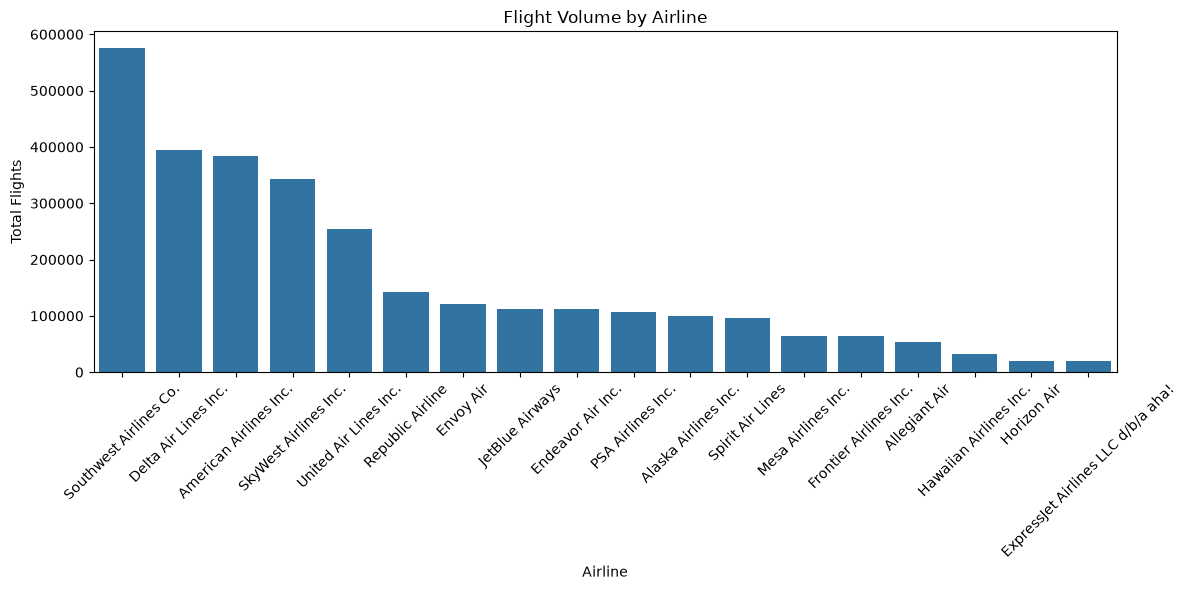

In [132]:
volume_plot = airline_kpi.sort_values(
    "TOTAL_FLIGHTS",
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=volume_plot,
    x="AIRLINE",
    y="TOTAL_FLIGHTS"
)

plt.title("Flight Volume by Airline")
plt.xlabel("Airline")
plt.ylabel("Total Flights")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

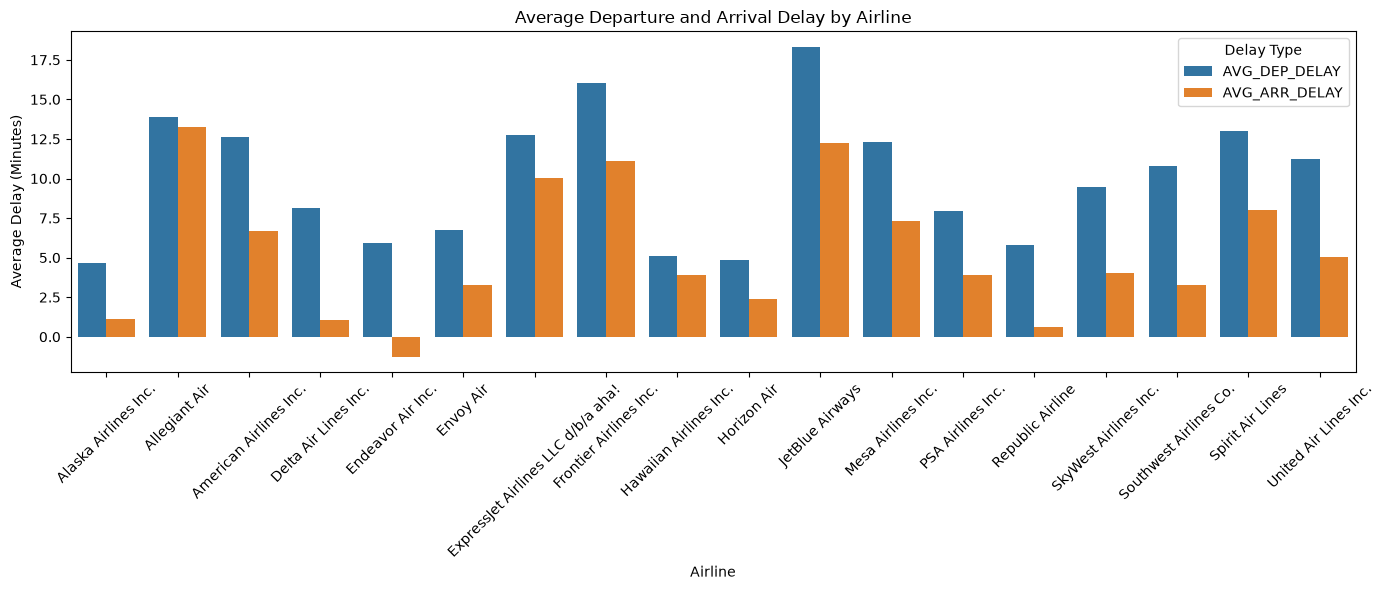

In [133]:
delay_plot = airline_kpi.melt(
    id_vars="AIRLINE",
    value_vars=["AVG_DEP_DELAY", "AVG_ARR_DELAY"],
    var_name="DELAY_TYPE",
    value_name="AVERAGE_DELAY"
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=delay_plot,
    x="AIRLINE",
    y="AVERAGE_DELAY",
    hue="DELAY_TYPE"
)

plt.title("Average Departure and Arrival Delay by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=45)
plt.legend(title="Delay Type")
plt.tight_layout()
plt.show()

In [134]:
cleaned_df["DELAY_SEVERITY"].value_counts(dropna=False)

DELAY_SEVERITY
ON_TIME              2398513
MODERATE_DELAY        184218
SEVERE_DELAY          175135
SIGNIFICANT_DELAY     155936
UNKNOWN                86198
Name: count, dtype: int64

In [135]:
severe_delay_rate = (
    cleaned_df.groupby("AIRLINE")["DELAY_SEVERITY"]
    .apply(lambda x: (x == "SEVERE_DELAY").mean())
    .reset_index(name="SEVERE_DELAY_RATE")
)

severe_delay_rate

,AIRLINE,SEVERE_DELAY_RATE
0,Alaska Airlines Inc.,0.041098
1,Allegiant Air,0.085005
2,American Airlines Inc.,0.067149
3,Delta Air Lines Inc.,0.043870
4,Endeavor Air Inc.,0.048185
5,Envoy Air,0.051783
6,ExpressJet Airlines LLC d/b/a aha!,0.082643
7,Frontier Airlines Inc.,0.096904
8,Hawaiian Airlines Inc.,0.024787
9,Horizon Air,0.036154


In [136]:
airline_kpi = airline_kpi.drop(
    columns=["SEVERE_DELAY_RATE"],
    errors="ignore"
)

airline_kpi = airline_kpi.merge(
    severe_delay_rate,
    on="AIRLINE",
    how="left"
)

In [137]:
airline_kpi["SEVERE_DELAY_RATE"] = (
    airline_kpi["SEVERE_DELAY_RATE"] * 100
)

airline_kpi[
    ["AIRLINE", "SEVERE_DELAY_RATE"]
].sort_values(
    "SEVERE_DELAY_RATE",
    ascending=False
)

,AIRLINE,SEVERE_DELAY_RATE
10,JetBlue Airways,10.816703
7,Frontier Airlines Inc.,9.690379
1,Allegiant Air,8.500512
6,ExpressJet Airlines LLC d/b/a aha!,8.264333
16,Spirit Air Lines,7.671010
11,Mesa Airlines Inc.,7.415554
2,American Airlines Inc.,6.714852
17,United Air Lines Inc.,6.654119
12,PSA Airlines Inc.,5.942083
14,SkyWest Airlines Inc.,5.872804


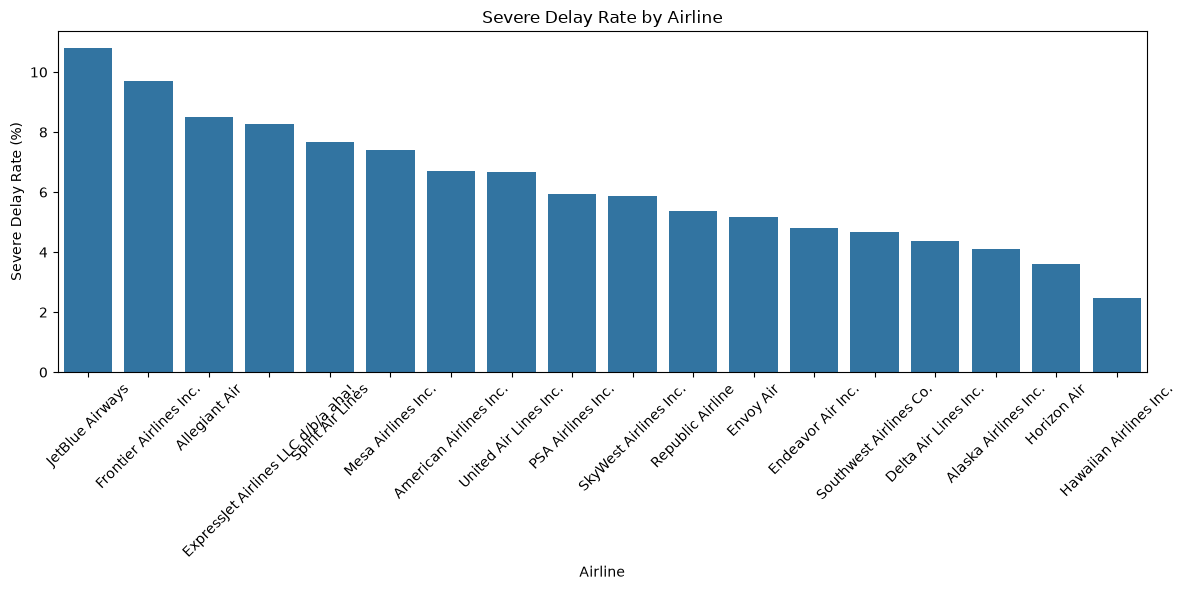

In [138]:
severe_plot = airline_kpi.sort_values(
    "SEVERE_DELAY_RATE",
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=severe_plot,
    x="AIRLINE",
    y="SEVERE_DELAY_RATE"
)

plt.title("Severe Delay Rate by Airline")
plt.xlabel("Airline")
plt.ylabel("Severe Delay Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

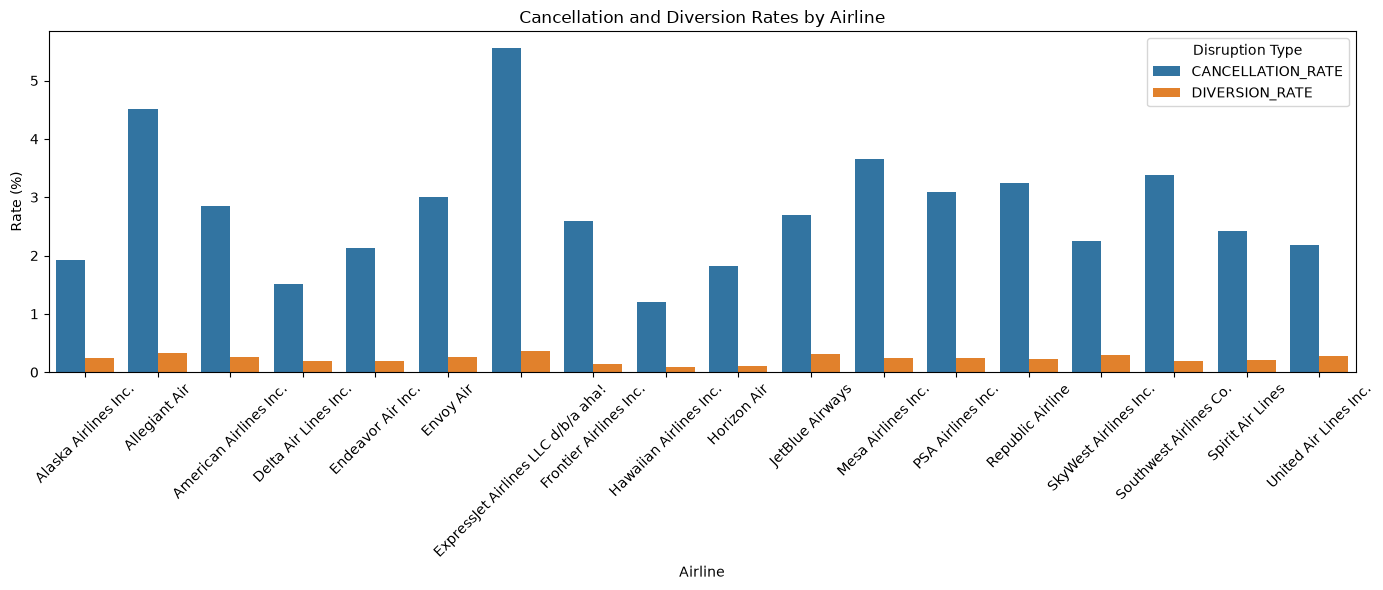

In [139]:
disruption_plot = airline_kpi.melt(
    id_vars="AIRLINE",
    value_vars=["CANCELLATION_RATE", "DIVERSION_RATE"],
    var_name="DISRUPTION_TYPE",
    value_name="RATE"
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=disruption_plot,
    x="AIRLINE",
    y="RATE",
    hue="DISRUPTION_TYPE"
)

plt.title("Cancellation and Diversion Rates by Airline")
plt.xlabel("Airline")
plt.ylabel("Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Disruption Type")
plt.tight_layout()
plt.show()

In [140]:
airline_kpi.sort_values(
    "AVG_ARR_DELAY",
    ascending=False
)

,AIRLINE,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,CANCELLATION_RATE,DIVERSION_RATE,SEVERE_DELAY_RATE
1,Allegiant Air,52738,13.907797,13.284601,4.518563,0.333725,8.500512
10,JetBlue Airways,112844,18.322555,12.276125,2.693098,0.317252,10.816703
7,Frontier Airlines Inc.,64466,16.033574,11.100429,2.584308,0.136506,9.690379
6,ExpressJet Airlines LLC d/b/a aha!,19082,12.774462,10.031976,5.565454,0.361597,8.264333
16,Spirit Air Lines,95711,12.981880,8.029485,2.415605,0.207918,7.671010
11,Mesa Airlines Inc.,65012,12.277383,7.309810,3.650095,0.249185,7.415554
2,American Airlines Inc.,383106,12.609895,6.661229,2.846993,0.256065,6.714852
17,United Air Lines Inc.,254504,11.217032,5.035985,2.175211,0.274259,6.654119
14,SkyWest Airlines Inc.,343737,9.458294,4.023311,2.253176,0.292666,5.872804
12,PSA Airlines Inc.,107050,7.972124,3.928655,3.083606,0.248482,5.942083


## Rule-Based Airline Performance Score

### Purpose
Create a transparent airline-level operational performance score.

### Input KPIs
1. Average Arrival Delay
2. Severe Delay Rate
3. Cancellation Rate
4. Diversion Rate

### Normalization
Because the KPIs have different units and scales, each KPI is
normalized using Min-Max normalization.

For each KPI:

Normalized KPI =
(Maximum - Airline Value) / (Maximum - Minimum)

This converts the metric into a 0–1 scale where:
- 1 = better relative performance
- 0 = poorer relative performance

### Business Weight Assumption
The project PDF requires documented business weights but does not
specify exact weights. Therefore, this analysis uses equal weights
as a transparent baseline:

- Average Arrival Delay = 25%
- Severe Delay Rate = 25%
- Cancellation Rate = 25%
- Diversion Rate = 25%

### Final Score

Airline Performance Score =
0.25 × Normalized Arrival Delay
+ 0.25 × Normalized Severe Delay Rate
+ 0.25 × Normalized Cancellation Rate
+ 0.25 × Normalized Diversion Rate

Higher score indicates better relative performance within this dataset.

This is a rule-based analytical score, not a machine-learning model.

In [141]:
score_df = airline_kpi[
    [
        "AIRLINE",
        "AVG_ARR_DELAY",
        "SEVERE_DELAY_RATE",
        "CANCELLATION_RATE",
        "DIVERSION_RATE"
    ]
].copy()

In [142]:
score_columns = [
    "AVG_ARR_DELAY",
    "SEVERE_DELAY_RATE",
    "CANCELLATION_RATE",
    "DIVERSION_RATE"
]

for column in score_columns:
    minimum = score_df[column].min()
    maximum = score_df[column].max()
    
    score_df[column + "_NORMALIZED"] = (
        (maximum - score_df[column]) /
        (maximum - minimum)
    )

score_df

,AIRLINE,AVG_ARR_DELAY,SEVERE_DELAY_RATE,CANCELLATION_RATE,DIVERSION_RATE,AVG_ARR_DELAY_NORMALIZED,SEVERE_DELAY_RATE_NORMALIZED,CANCELLATION_RATE_NORMALIZED,DIVERSION_RATE_NORMALIZED
0,Alaska Airlines Inc.,1.097900,4.109807,1.925010,0.237889,0.837969,0.804374,0.835490,0.450819
1,Allegiant Air,13.284601,8.500512,4.518563,0.333725,0.000000,0.277786,0.240264,0.101572
2,American Airlines Inc.,6.661229,6.714852,2.846993,0.256065,0.455429,0.491945,0.623893,0.384582
3,Delta Air Lines Inc.,1.085079,4.386966,1.513515,0.197855,0.838851,0.771134,0.929929,0.596711
4,Endeavor Air Inc.,-1.258539,4.818474,2.128700,0.196509,1.000000,0.719382,0.788742,0.601616
5,Envoy Air,3.278914,5.178300,2.996140,0.256482,0.688000,0.676227,0.589663,0.383062
6,ExpressJet Airlines LLC d/b/a aha!,10.031976,8.264333,5.565454,0.361597,0.223654,0.306112,0.000000,0.000000
7,Frontier Airlines Inc.,11.100429,9.690379,2.584308,0.136506,0.150186,0.135083,0.684179,0.820280
8,Hawaiian Airlines Inc.,3.894757,2.478670,1.208196,0.087189,0.645655,1.000000,1.000000,1.000000
9,Horizon Air,2.376242,3.615392,1.812542,0.111467,0.750069,0.863670,0.861301,0.911529


In [143]:
score_df["AIRLINE_PERFORMANCE_SCORE"] = (
    score_df["AVG_ARR_DELAY_NORMALIZED"] * 0.25
    + score_df["SEVERE_DELAY_RATE_NORMALIZED"] * 0.25
    + score_df["CANCELLATION_RATE_NORMALIZED"] * 0.25
    + score_df["DIVERSION_RATE_NORMALIZED"] * 0.25
)

In [144]:
airline_ranking = score_df.sort_values(
    "AIRLINE_PERFORMANCE_SCORE",
    ascending=False
).reset_index(drop=True)

airline_ranking[
    [
        "AIRLINE",
        "AIRLINE_PERFORMANCE_SCORE",
        "AVG_ARR_DELAY",
        "SEVERE_DELAY_RATE",
        "CANCELLATION_RATE",
        "DIVERSION_RATE"
    ]
]

,AIRLINE,AIRLINE_PERFORMANCE_SCORE,AVG_ARR_DELAY,SEVERE_DELAY_RATE,CANCELLATION_RATE,DIVERSION_RATE
0,Hawaiian Airlines Inc.,0.911414,3.894757,2.478670,1.208196,0.087189
1,Horizon Air,0.846642,2.376242,3.615392,1.812542,0.111467
2,Delta Air Lines Inc.,0.784156,1.085079,4.386966,1.513515,0.197855
3,Endeavor Air Inc.,0.777435,-1.258539,4.818474,2.128700,0.196509
4,Alaska Airlines Inc.,0.732163,1.097900,4.109807,1.925010,0.237889
5,Republic Airline,0.645124,0.590176,5.357530,3.246522,0.218717
6,Southwest Airlines Co.,0.632177,3.269796,4.662168,3.376585,0.197061
7,Envoy Air,0.584238,3.278914,5.178300,2.996140,0.256482
8,SkyWest Airlines Inc.,0.560281,4.023311,5.872804,2.253176,0.292666
9,PSA Airlines Inc.,0.552438,3.928655,5.942083,3.083606,0.248482


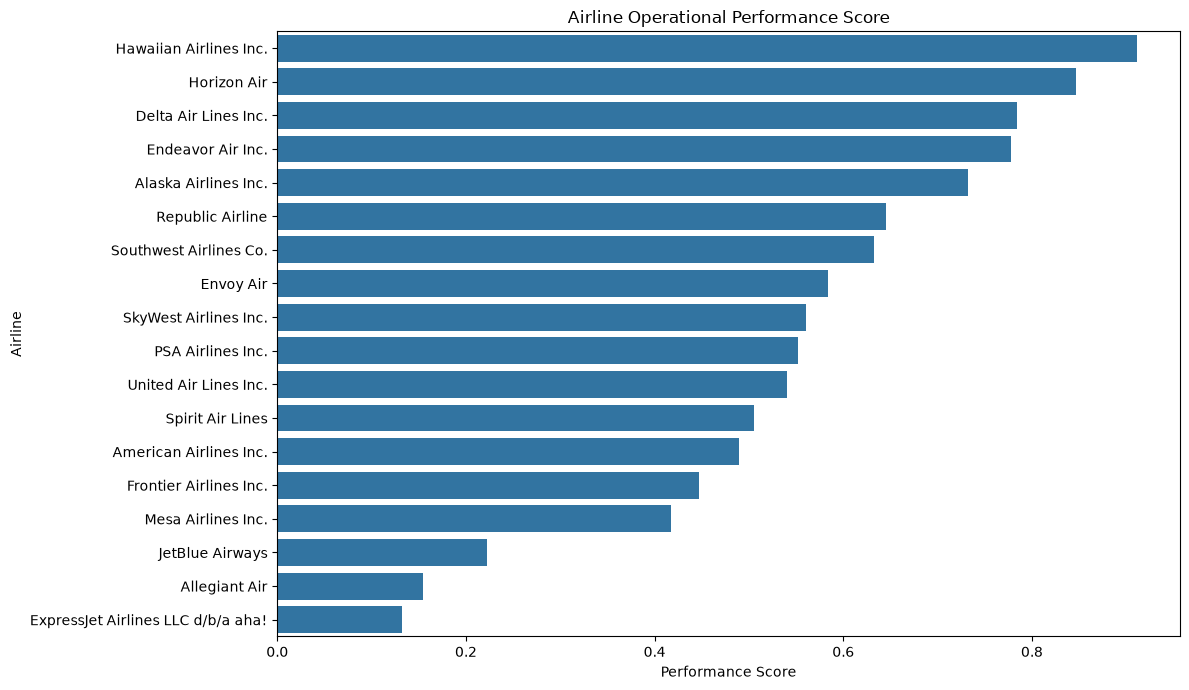

In [145]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=airline_ranking,
    x="AIRLINE_PERFORMANCE_SCORE",
    y="AIRLINE"
)

plt.title("Airline Operational Performance Score")
plt.xlabel("Performance Score")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()

In [146]:
airline_ranking[
    [
        "AIRLINE",
        "AIRLINE_PERFORMANCE_SCORE",
        "AVG_ARR_DELAY",
        "SEVERE_DELAY_RATE",
        "CANCELLATION_RATE",
        "DIVERSION_RATE"
    ]
].tail()

,AIRLINE,AIRLINE_PERFORMANCE_SCORE,AVG_ARR_DELAY,SEVERE_DELAY_RATE,CANCELLATION_RATE,DIVERSION_RATE
13,Frontier Airlines Inc.,0.447432,11.100429,9.690379,2.584308,0.136506
14,Mesa Airlines Inc.,0.416993,7.309810,7.415554,3.650095,0.249185
15,JetBlue Airways,0.222540,12.276125,10.816703,2.693098,0.317252
16,Allegiant Air,0.154905,13.284601,8.500512,4.518563,0.333725
17,ExpressJet Airlines LLC d/b/a aha!,0.132441,10.031976,8.264333,5.565454,0.361597


## Business Answer — Airline Operational Performance

The analysis compares airline operational performance using flight volume,
average departure delay, average arrival delay, severe-delay rate,
cancellation rate, diversion rate and a normalized Airline Performance Score.

### Key Findings

- Hawaiian Airlines Inc. recorded the highest Airline Performance Score
  at 0.911, followed by Horizon Air at 0.847 and Delta Air Lines Inc.
  at 0.784. These airlines showed relatively stronger performance across
  the combined operational KPIs used in the scoring model.

- ExpressJet Airlines LLC d/b/a aha! recorded the lowest Airline
  Performance Score at 0.132, followed by Allegiant Air at 0.155 and
  JetBlue Airways at 0.223. These airlines showed relatively higher
  operational exposure across the selected delay and disruption metrics.

- JetBlue Airways recorded the highest severe-delay rate at approximately
  10.82%, followed by Frontier Airlines Inc. at 9.69% and Allegiant Air
  at 8.50%.

- Hawaiian Airlines Inc. recorded the lowest severe-delay rate at
  approximately 2.48%, while Horizon Air recorded approximately 3.62%.
  :contentReference[oaicite:1]{index=1}

- JetBlue Airways also recorded the highest average departure delay
  (18.32 minutes) and a high average arrival delay (12.28 minutes).
  Allegiant Air recorded an average arrival delay of 13.28 minutes.
  :contentReference[oaicite:2]{index=2}

- ExpressJet Airlines LLC d/b/a aha! had the highest cancellation rate
  at approximately 5.57% and the highest diversion rate at approximately
  0.36% among the airlines in this analysis. :contentReference[oaicite:3]{index=3}

### Operational Interpretation

The results show that airline performance differs across multiple
operational dimensions. Therefore, flight volume or a single delay
metric should not be used alone to evaluate airline performance.

The normalized Airline Performance Score provides a combined view of
average arrival delay, severe-delay rate, cancellation rate and
diversion rate. The score is intended as a transparent rule-based
benchmark for this dataset rather than as a standalone measure of
overall airline quality.

Airlines with lower scores can be prioritized for further operational
investigation by examining their specific delay, cancellation and
diversion patterns.

### Business Conclusion

The airline comparison identifies meaningful differences in operational
reliability across the dataset. Hawaiian Airlines Inc., Horizon Air and
Delta Air Lines Inc. achieved the highest scores under the documented
scoring framework, while ExpressJet Airlines LLC d/b/a aha!, Allegiant
Air and JetBlue Airways recorded the lowest scores.

The next stage of analysis should examine airport and route-level delay
burden to determine whether these airline-level patterns are associated
with specific operational locations or routes.

# Business Question 2: Airport and Route Delay Burden

## Business Question
Which airports and routes have the highest delay burden?

## Objective
Identify airports and routes with high operational delay exposure by
combining flight volume, delay frequency, delay severity and disruption.

The analysis will:
1. Identify high-volume airports.
2. Compare airport delay performance.
3. Identify airports with high delay burden.
4. Build an Airport Risk Score.
5. Analyze route-level delay performance.
6. Identify high-risk routes.
7. Build a Route Risk Score.
8. Identify airports and routes requiring operational attention.

## Airport-Level KPI Development

Airport performance will be evaluated using:

- Total flights
- Average arrival delay
- Delayed-flight rate
- Severe-delay rate
- Cancellation rate
- Diversion rate
- Total arrival delay minutes

These metrics provide both volume and reliability perspectives.

In [147]:
airport_kpi = (
    cleaned_df.groupby("ORIGIN")
    .agg(
        TOTAL_FLIGHTS=("FL_DATE", "count"),
        AVG_ARR_DELAY=("ARR_DELAY", "mean"),
        TOTAL_ARR_DELAY_MINUTES=("ARR_DELAY", "sum"),
        CANCELLATION_RATE=("CANCELLED", "mean"),
        DIVERSION_RATE=("DIVERTED", "mean")
    )
    .reset_index()
)

airport_kpi

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,TOTAL_ARR_DELAY_MINUTES,CANCELLATION_RATE,DIVERSION_RATE
0,ABE,2023,1.535333,3020.0,0.025210,0.002472
1,ABI,901,6.550343,5725.0,0.029967,0.000000
2,ABQ,9284,3.598339,32493.0,0.025205,0.002154
3,ABR,332,7.625000,2501.0,0.012048,0.000000
4,ABY,436,-2.437209,-1048.0,0.011468,0.002294
...,...,...,...,...,...,...
375,XNA,4980,7.111180,34411.0,0.024699,0.003614
376,XWA,433,15.063107,6206.0,0.043880,0.004619
377,YAK,323,0.520767,163.0,0.021672,0.009288
378,YKM,152,1.979730,293.0,0.026316,0.000000


In [148]:
airport_delay_rate = (
    cleaned_df.groupby("ORIGIN")["ARR_DELAY"]
    .apply(lambda x: (x > 0).mean())
    .reset_index(name="DELAYED_FLIGHT_RATE")
)

airport_kpi = airport_kpi.merge(
    airport_delay_rate,
    on="ORIGIN",
    how="left"
)

airport_kpi

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,TOTAL_ARR_DELAY_MINUTES,CANCELLATION_RATE,DIVERSION_RATE,DELAYED_FLIGHT_RATE
0,ABE,2023,1.535333,3020.0,0.025210,0.002472,0.279783
1,ABI,901,6.550343,5725.0,0.029967,0.000000,0.357381
2,ABQ,9284,3.598339,32493.0,0.025205,0.002154,0.308595
3,ABR,332,7.625000,2501.0,0.012048,0.000000,0.219880
4,ABY,436,-2.437209,-1048.0,0.011468,0.002294,0.197248
...,...,...,...,...,...,...,...
375,XNA,4980,7.111180,34411.0,0.024699,0.003614,0.332129
376,XWA,433,15.063107,6206.0,0.043880,0.004619,0.318707
377,YAK,323,0.520767,163.0,0.021672,0.009288,0.312693
378,YKM,152,1.979730,293.0,0.026316,0.000000,0.315789


In [149]:
airport_severe_rate = (
    cleaned_df.groupby("ORIGIN")["DELAY_SEVERITY"]
    .apply(lambda x: (x == "SEVERE_DELAY").mean())
    .reset_index(name="SEVERE_DELAY_RATE")
)

airport_kpi = airport_kpi.merge(
    airport_severe_rate,
    on="ORIGIN",
    how="left"
)

airport_kpi

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,TOTAL_ARR_DELAY_MINUTES,CANCELLATION_RATE,DIVERSION_RATE,DELAYED_FLIGHT_RATE,SEVERE_DELAY_RATE
0,ABE,2023,1.535333,3020.0,0.025210,0.002472,0.279783,0.058329
1,ABI,901,6.550343,5725.0,0.029967,0.000000,0.357381,0.065483
2,ABQ,9284,3.598339,32493.0,0.025205,0.002154,0.308595,0.048147
3,ABR,332,7.625000,2501.0,0.012048,0.000000,0.219880,0.060241
4,ABY,436,-2.437209,-1048.0,0.011468,0.002294,0.197248,0.034404
...,...,...,...,...,...,...,...,...
375,XNA,4980,7.111180,34411.0,0.024699,0.003614,0.332129,0.067671
376,XWA,433,15.063107,6206.0,0.043880,0.004619,0.318707,0.083141
377,YAK,323,0.520767,163.0,0.021672,0.009288,0.312693,0.037152
378,YKM,152,1.979730,293.0,0.026316,0.000000,0.315789,0.019737


In [150]:
airport_kpi["DELAYED_FLIGHT_RATE"] = (
    airport_kpi["DELAYED_FLIGHT_RATE"] * 100
)

airport_kpi["SEVERE_DELAY_RATE"] = (
    airport_kpi["SEVERE_DELAY_RATE"] * 100
)

airport_kpi["CANCELLATION_RATE"] = (
    airport_kpi["CANCELLATION_RATE"] * 100
)

airport_kpi["DIVERSION_RATE"] = (
    airport_kpi["DIVERSION_RATE"] * 100
)

airport_kpi

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,TOTAL_ARR_DELAY_MINUTES,CANCELLATION_RATE,DIVERSION_RATE,DELAYED_FLIGHT_RATE,SEVERE_DELAY_RATE
0,ABE,2023,1.535333,3020.0,2.521008,0.247158,27.978250,5.832921
1,ABI,901,6.550343,5725.0,2.996670,0.000000,35.738069,6.548280
2,ABQ,9284,3.598339,32493.0,2.520465,0.215424,30.859543,4.814735
3,ABR,332,7.625000,2501.0,1.204819,0.000000,21.987952,6.024096
4,ABY,436,-2.437209,-1048.0,1.146789,0.229358,19.724771,3.440367
...,...,...,...,...,...,...,...,...
375,XNA,4980,7.111180,34411.0,2.469880,0.361446,33.212851,6.767068
376,XWA,433,15.063107,6206.0,4.387991,0.461894,31.870670,8.314088
377,YAK,323,0.520767,163.0,2.167183,0.928793,31.269350,3.715170
378,YKM,152,1.979730,293.0,2.631579,0.000000,31.578947,1.973684


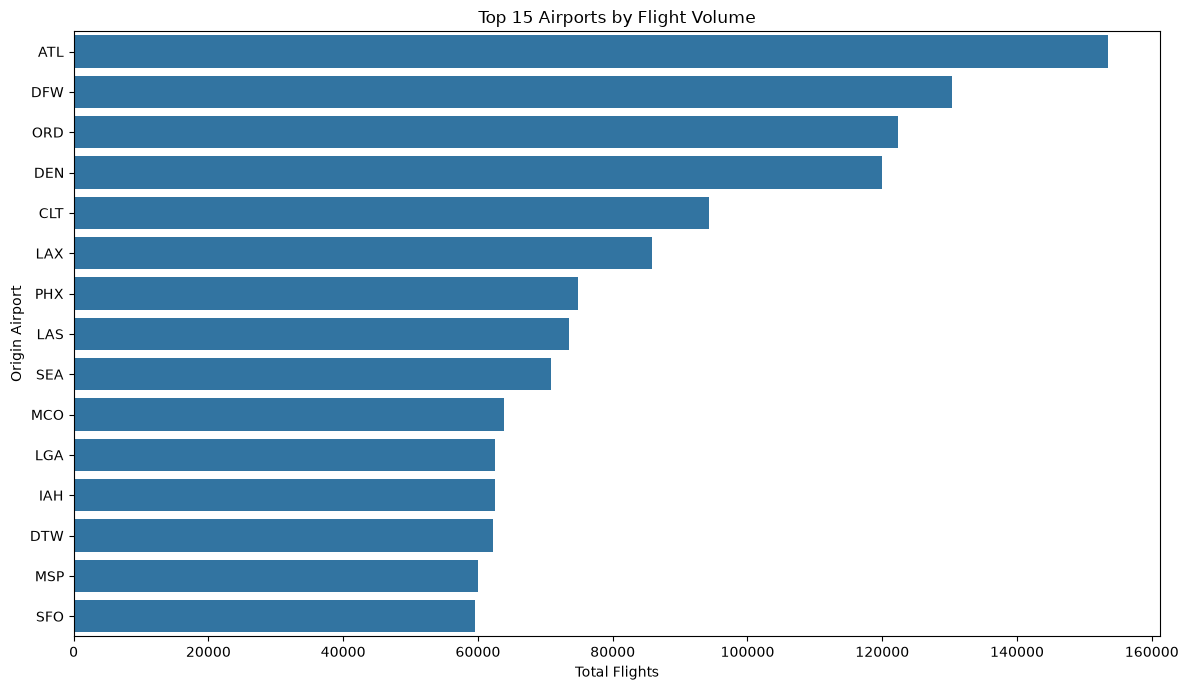

In [151]:
top_volume_airports = airport_kpi.sort_values(
    "TOTAL_FLIGHTS",
    ascending=False
).head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_volume_airports,
    x="TOTAL_FLIGHTS",
    y="ORIGIN"
)

plt.title("Top 15 Airports by Flight Volume")
plt.xlabel("Total Flights")
plt.ylabel("Origin Airport")

plt.tight_layout()
plt.show()

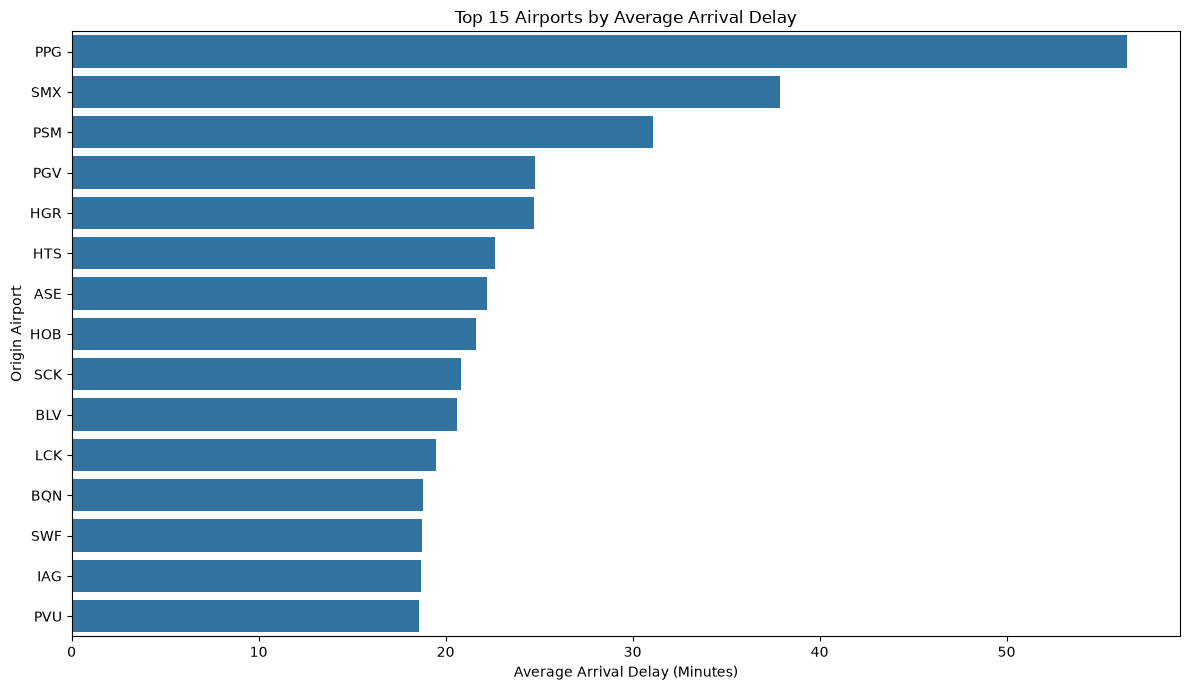

In [152]:
airport_delay_plot = airport_kpi.sort_values(
    "AVG_ARR_DELAY",
    ascending=False
).head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=airport_delay_plot,
    x="AVG_ARR_DELAY",
    y="ORIGIN"
)

plt.title("Top 15 Airports by Average Arrival Delay")
plt.xlabel("Average Arrival Delay (Minutes)")
plt.ylabel("Origin Airport")

plt.tight_layout()
plt.show()

In [153]:
airport_burden = airport_kpi.sort_values(
    "TOTAL_ARR_DELAY_MINUTES",
    ascending=False
)

airport_burden.head(15)

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,TOTAL_ARR_DELAY_MINUTES,CANCELLATION_RATE,DIVERSION_RATE,DELAYED_FLIGHT_RATE,SEVERE_DELAY_RATE
100,DFW,130334,8.376381,1053531.0,3.220188,0.278515,36.975770,7.227585
99,DEN,119919,7.380798,858837.0,2.721003,0.245165,38.434276,6.733712
261,ORD,122296,6.062906,716684.0,3.096585,0.246124,34.404232,7.028030
223,MCO,63883,9.878134,612711.0,2.725295,0.180017,38.739571,8.512437
199,LAS,73470,6.609685,472143.0,2.575201,0.198721,38.234654,6.048727
123,EWR,52989,8.666155,440310.0,3.872502,0.243447,36.603823,9.130197
77,CLT,94304,4.365559,400623.0,2.472854,0.215261,34.082329,5.664659
23,ATL,153556,2.587002,389988.0,1.602673,0.225325,30.818724,4.380812
234,MIA,41981,8.700904,355954.0,2.262928,0.288226,37.588433,7.505776
174,IAH,62542,5.637249,343331.0,2.377602,0.241438,33.113748,6.629145


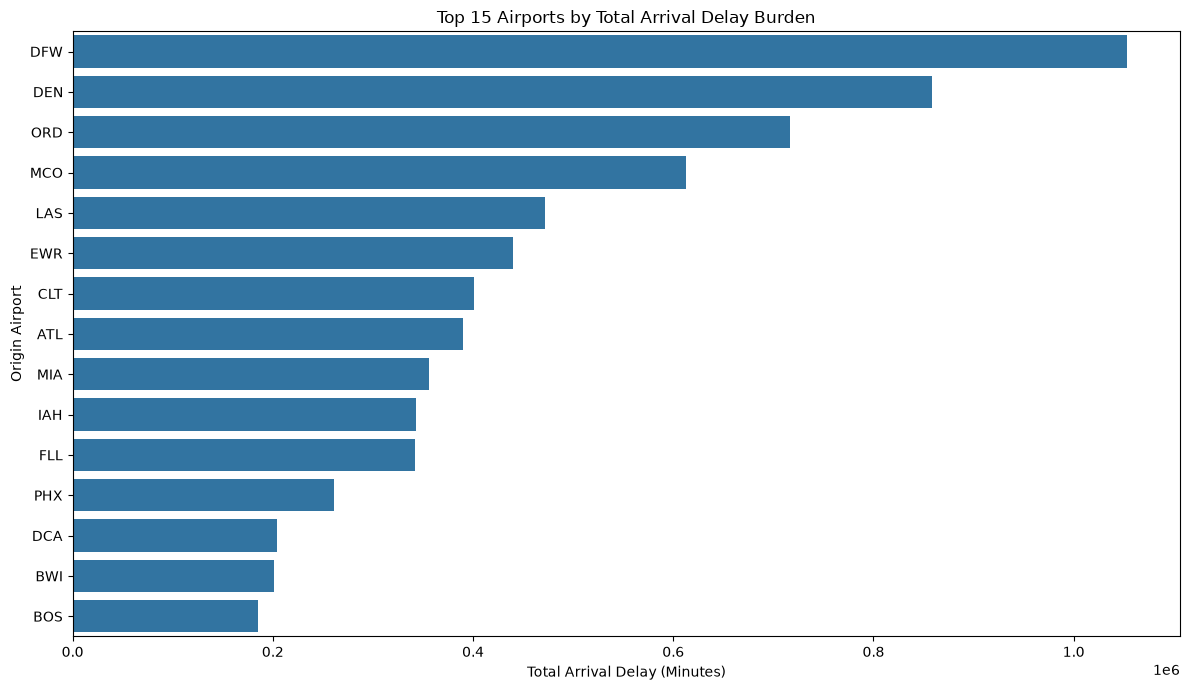

In [154]:
top_burden_airports = airport_burden.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_burden_airports,
    x="TOTAL_ARR_DELAY_MINUTES",
    y="ORIGIN"
)

plt.title("Top 15 Airports by Total Arrival Delay Burden")
plt.xlabel("Total Arrival Delay (Minutes)")
plt.ylabel("Origin Airport")

plt.tight_layout()
plt.show()

## Rule-Based Airport Risk Score

### Purpose
Identify airports with relatively high operational risk.

### Inputs
1. Delayed-flight rate
2. Severe-delay rate
3. Disruption rate

### Disruption Rate

Disruption Rate =
Cancellation Rate + Diversion Rate

### Normalization

Each risk KPI is normalized using Min-Max normalization:

Normalized Risk =
(Value - Minimum) / (Maximum - Minimum)

A higher normalized value represents higher relative operational risk.

### Airport Risk Score

Airport Risk Score =
0.3333 × Normalized Delayed-Flight Rate
+ 0.3333 × Normalized Severe-Delay Rate
+ 0.3334 × Normalized Disruption Rate

Equal weights are used as a transparent baseline because the project
PDF requires documented weights but does not prescribe specific weights.

Higher Airport Risk Score indicates higher relative operational risk
within this dataset.

This is a rule-based analytical score and not a machine-learning model.

In [155]:
airport_kpi["DISRUPTION_RATE"] = (
    airport_kpi["CANCELLATION_RATE"]
    + airport_kpi["DIVERSION_RATE"]
)

airport_kpi[
    [
        "ORIGIN",
        "DELAYED_FLIGHT_RATE",
        "SEVERE_DELAY_RATE",
        "DISRUPTION_RATE"
    ]
]

,ORIGIN,DELAYED_FLIGHT_RATE,SEVERE_DELAY_RATE,DISRUPTION_RATE
0,ABE,27.978250,5.832921,2.768166
1,ABI,35.738069,6.548280,2.996670
2,ABQ,30.859543,4.814735,2.735890
3,ABR,21.987952,6.024096,1.204819
4,ABY,19.724771,3.440367,1.376147
...,...,...,...,...
375,XNA,33.212851,6.767068,2.831325
376,XWA,31.870670,8.314088,4.849885
377,YAK,31.269350,3.715170,3.095975
378,YKM,31.578947,1.973684,2.631579


In [156]:
airport_score = airport_kpi[
    [
        "ORIGIN",
        "DELAYED_FLIGHT_RATE",
        "SEVERE_DELAY_RATE",
        "DISRUPTION_RATE"
    ]
].copy()

risk_columns = [
    "DELAYED_FLIGHT_RATE",
    "SEVERE_DELAY_RATE",
    "DISRUPTION_RATE"
]

for column in risk_columns:
    minimum = airport_score[column].min()
    maximum = airport_score[column].max()

    airport_score[column + "_NORMALIZED"] = (
        (airport_score[column] - minimum)
        / (maximum - minimum)
    )

airport_score

,ORIGIN,DELAYED_FLIGHT_RATE,SEVERE_DELAY_RATE,DISRUPTION_RATE,DELAYED_FLIGHT_RATE_NORMALIZED,SEVERE_DELAY_RATE_NORMALIZED,DISRUPTION_RATE_NORMALIZED
0,ABE,27.978250,5.832921,2.768166,0.320727,0.349975,0.124567
1,ABI,35.738069,6.548280,2.996670,0.442038,0.392897,0.134850
2,ABQ,30.859543,4.814735,2.735890,0.365771,0.288884,0.123115
3,ABR,21.987952,6.024096,1.204819,0.227078,0.361446,0.054217
4,ABY,19.724771,3.440367,1.376147,0.191697,0.206422,0.061927
...,...,...,...,...,...,...,...
375,XNA,33.212851,6.767068,2.831325,0.402561,0.406024,0.127410
376,XWA,31.870670,8.314088,4.849885,0.381578,0.498845,0.218245
377,YAK,31.269350,3.715170,3.095975,0.372178,0.222910,0.139319
378,YKM,31.578947,1.973684,2.631579,0.377018,0.118421,0.118421


In [157]:
airport_score["AIRPORT_RISK_SCORE"] = (
    airport_score["DELAYED_FLIGHT_RATE_NORMALIZED"] * 0.3333
    + airport_score["SEVERE_DELAY_RATE_NORMALIZED"] * 0.3333
    + airport_score["DISRUPTION_RATE_NORMALIZED"] * 0.3334
)

In [158]:
airport_ranking = airport_score.sort_values(
    "AIRPORT_RISK_SCORE",
    ascending=False
).reset_index(drop=True)

airport_ranking

,ORIGIN,DELAYED_FLIGHT_RATE,SEVERE_DELAY_RATE,DISRUPTION_RATE,DELAYED_FLIGHT_RATE_NORMALIZED,SEVERE_DELAY_RATE_NORMALIZED,DISRUPTION_RATE_NORMALIZED,AIRPORT_RISK_SCORE
0,ART,42.857143,14.285714,14.285714,0.553333,0.857143,0.642857,0.684440
1,OGD,50.000000,5.555556,22.222222,0.665000,0.333333,1.000000,0.666144
2,HYA,42.000000,16.000000,6.000000,0.539933,0.960000,0.270000,0.589946
3,ASE,38.509969,12.556838,9.898566,0.485373,0.753410,0.445435,0.561394
4,HTS,49.572650,12.393162,5.982906,0.658319,0.743590,0.269231,0.557018
...,...,...,...,...,...,...,...,...
375,VCT,10.000000,2.941176,4.117647,0.039667,0.176471,0.185294,0.133816
376,SCC,17.605634,1.760563,2.816901,0.158568,0.105634,0.126761,0.130320
377,ISN,24.561404,1.754386,0.000000,0.267310,0.105263,0.000000,0.124179
378,GUM,23.437500,1.250000,0.937500,0.249740,0.075000,0.042188,0.122301


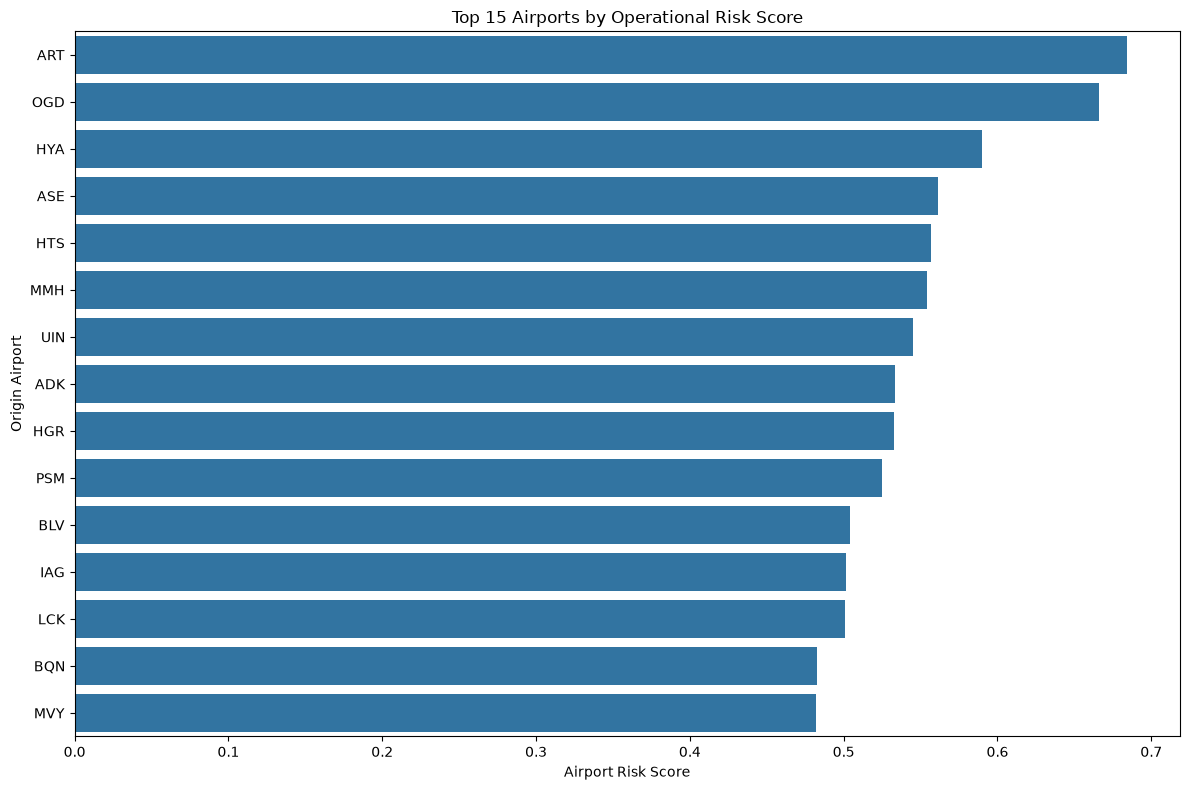

In [159]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=airport_ranking.head(15),
    x="AIRPORT_RISK_SCORE",
    y="ORIGIN"
)

plt.title("Top 15 Airports by Operational Risk Score")
plt.xlabel("Airport Risk Score")
plt.ylabel("Origin Airport")

plt.tight_layout()
plt.show()

## Route-Level KPI Development

Routes will be evaluated using:

- Total flights
- Average arrival delay
- Delayed-flight rate
- Severe-delay rate
- Cancellation rate
- Diversion rate
- Total arrival delay minutes

This allows route frequency, severity and disruption exposure to be
compared consistently.

In [160]:
route_kpi = (
    cleaned_df.groupby("ROUTE")
    .agg(
        TOTAL_FLIGHTS=("FL_DATE", "count"),
        AVG_ARR_DELAY=("ARR_DELAY", "mean"),
        TOTAL_ARR_DELAY_MINUTES=("ARR_DELAY", "sum"),
        CANCELLATION_RATE=("CANCELLED", "mean"),
        DIVERSION_RATE=("DIVERTED", "mean")
    )
    .reset_index()
)

route_kpi

,ROUTE,TOTAL_FLIGHTS,AVG_ARR_DELAY,TOTAL_ARR_DELAY_MINUTES,CANCELLATION_RATE,DIVERSION_RATE
0,ABE → ATL,398,6.190840,2433.0,0.012563,0.000000
1,ABE → BNA,48,16.181818,712.0,0.083333,0.000000
2,ABE → CLT,483,-14.505330,-6803.0,0.026915,0.002070
3,ABE → DEN,1,-7.000000,-7.0,0.000000,0.000000
4,ABE → DTW,292,4.780488,1372.0,0.013699,0.003425
...,...,...,...,...,...,...
7780,YAK → CDV,155,2.858108,423.0,0.025806,0.019355
7781,YAK → JNU,168,-1.575758,-260.0,0.017857,0.000000
7782,YKM → SEA,152,1.979730,293.0,0.026316,0.000000
7783,YUM → DFW,210,10.786408,2222.0,0.014286,0.004762


In [161]:
route_delay_rate = (
    cleaned_df.groupby("ROUTE")["ARR_DELAY"]
    .apply(lambda x: (x > 0).mean())
    .reset_index(name="DELAYED_FLIGHT_RATE")
)

route_kpi = route_kpi.merge(
    route_delay_rate,
    on="ROUTE",
    how="left"
)

In [162]:
route_severe_rate = (
    cleaned_df.groupby("ROUTE")["DELAY_SEVERITY"]
    .apply(lambda x: (x == "SEVERE_DELAY").mean())
    .reset_index(name="SEVERE_DELAY_RATE")
)

route_kpi = route_kpi.merge(
    route_severe_rate,
    on="ROUTE",
    how="left"
)

In [163]:
route_kpi["DELAYED_FLIGHT_RATE"] *= 100
route_kpi["SEVERE_DELAY_RATE"] *= 100
route_kpi["CANCELLATION_RATE"] *= 100
route_kpi["DIVERSION_RATE"] *= 100

route_kpi["DISRUPTION_RATE"] = (
    route_kpi["CANCELLATION_RATE"]
    + route_kpi["DIVERSION_RATE"]
)

route_kpi

,ROUTE,TOTAL_FLIGHTS,AVG_ARR_DELAY,TOTAL_ARR_DELAY_MINUTES,CANCELLATION_RATE,DIVERSION_RATE,DELAYED_FLIGHT_RATE,SEVERE_DELAY_RATE,DISRUPTION_RATE
0,ABE → ATL,398,6.190840,2433.0,1.256281,0.000000,31.407035,6.281407,1.256281
1,ABE → BNA,48,16.181818,712.0,8.333333,0.000000,37.500000,12.500000,8.333333
2,ABE → CLT,483,-14.505330,-6803.0,2.691511,0.207039,16.770186,3.312629,2.898551
3,ABE → DEN,1,-7.000000,-7.0,0.000000,0.000000,0.000000,0.000000,0.000000
4,ABE → DTW,292,4.780488,1372.0,1.369863,0.342466,25.684932,6.849315,1.712329
...,...,...,...,...,...,...,...,...,...
7780,YAK → CDV,155,2.858108,423.0,2.580645,1.935484,33.548387,3.225806,4.516129
7781,YAK → JNU,168,-1.575758,-260.0,1.785714,0.000000,29.166667,4.166667,1.785714
7782,YKM → SEA,152,1.979730,293.0,2.631579,0.000000,31.578947,1.973684,2.631579
7783,YUM → DFW,210,10.786408,2222.0,1.428571,0.476190,20.952381,5.238095,1.904762


In [164]:
top_delayed_routes = route_kpi[
    route_kpi["TOTAL_FLIGHTS"] >= 100
].sort_values(
    "AVG_ARR_DELAY",
    ascending=False
).head(20)

top_delayed_routes

,ROUTE,TOTAL_FLIGHTS,AVG_ARR_DELAY,TOTAL_ARR_DELAY_MINUTES,CANCELLATION_RATE,DIVERSION_RATE,DELAYED_FLIGHT_RATE,SEVERE_DELAY_RATE,DISRUPTION_RATE
6319,RNO → JFK,101,47.412371,4599.0,3.960396,0.000000,52.475248,17.821782,3.960396
25,ABQ → JFK,116,40.100917,4371.0,6.034483,0.000000,45.689655,17.241379,6.034483
51,ACK → LGA,145,38.880597,5210.0,6.206897,1.379310,43.448276,17.931034,7.586207
173,ASE → ORD,407,38.536111,13873.0,11.056511,0.491400,39.312039,16.216216,11.547912
584,BDL → SJU,307,37.036667,11111.0,2.280130,0.000000,59.934853,18.892508,2.280130
5209,ONT → JFK,124,36.376068,4256.0,5.645161,0.000000,45.161290,13.709677,5.645161
3239,IAD → SHD,140,34.970588,4756.0,2.857143,0.000000,27.857143,12.142857,2.857143
7043,SJU → DCA,153,33.238411,5019.0,1.307190,0.000000,60.130719,16.339869,1.307190
168,ASE → DFW,411,33.197297,12283.0,8.759124,1.216545,40.389294,13.625304,9.975669
1157,CHO → ORD,142,33.000000,4455.0,4.929577,0.000000,46.478873,15.492958,4.929577


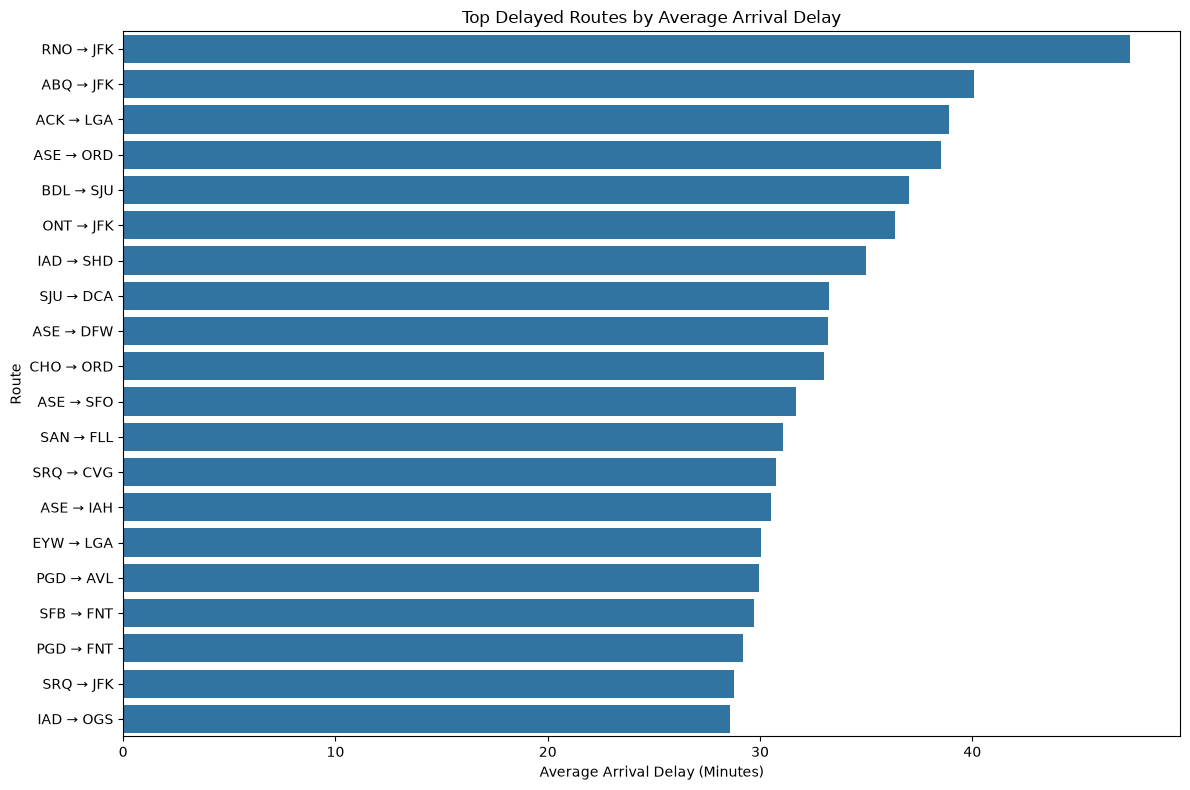

In [165]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_delayed_routes,
    x="AVG_ARR_DELAY",
    y="ROUTE"
)

plt.title("Top Delayed Routes by Average Arrival Delay")
plt.xlabel("Average Arrival Delay (Minutes)")
plt.ylabel("Route")

plt.tight_layout()
plt.show()

## Rule-Based Route Risk Score

### Purpose
Identify routes with relatively high operational risk.

### Inputs
1. Delayed-flight rate — delay frequency
2. Severe-delay rate — delay severity
3. Disruption rate — cancellation and diversion exposure

### Normalization

Normalized Risk =
(Value - Minimum) / (Maximum - Minimum)

### Route Risk Score

Route Risk Score =
0.3333 × Normalized Delay Frequency
+ 0.3333 × Normalized Delay Severity
+ 0.3334 × Normalized Disruption Rate

Equal weights are used as a transparent baseline because the project
PDF does not prescribe specific weights.

Higher Route Risk Score indicates higher relative operational risk
within the analyzed routes.

In [166]:
route_score = route_kpi[
    [
        "ROUTE",
        "DELAYED_FLIGHT_RATE",
        "SEVERE_DELAY_RATE",
        "DISRUPTION_RATE"
    ]
].copy()

risk_columns = [
    "DELAYED_FLIGHT_RATE",
    "SEVERE_DELAY_RATE",
    "DISRUPTION_RATE"
]

for column in risk_columns:
    minimum = route_score[column].min()
    maximum = route_score[column].max()

    route_score[column + "_NORMALIZED"] = (
        (route_score[column] - minimum)
        / (maximum - minimum)
    )

In [167]:
route_score["ROUTE_RISK_SCORE"] = (
    route_score["DELAYED_FLIGHT_RATE_NORMALIZED"] * 0.3333
    + route_score["SEVERE_DELAY_RATE_NORMALIZED"] * 0.3333
    + route_score["DISRUPTION_RATE_NORMALIZED"] * 0.3334
)

In [168]:
route_ranking = (
    route_score
    .merge(
        route_kpi[
            [
                "ROUTE",
                "TOTAL_FLIGHTS",
                "AVG_ARR_DELAY",
                "TOTAL_ARR_DELAY_MINUTES"
            ]
        ],
        on="ROUTE",
        how="left"
    )
)

high_risk_routes = (
    route_ranking[
        route_ranking["TOTAL_FLIGHTS"] >= 100
    ]
    .sort_values(
        "ROUTE_RISK_SCORE",
        ascending=False
    )
    .reset_index(drop=True)
)

high_risk_routes.head(20)

,ROUTE,DELAYED_FLIGHT_RATE,SEVERE_DELAY_RATE,DISRUPTION_RATE,DELAYED_FLIGHT_RATE_NORMALIZED,SEVERE_DELAY_RATE_NORMALIZED,DISRUPTION_RATE_NORMALIZED,ROUTE_RISK_SCORE,TOTAL_FLIGHTS,AVG_ARR_DELAY,TOTAL_ARR_DELAY_MINUTES
0,SRQ → CVG,61.607143,18.750000,3.571429,0.616071,0.187500,0.035714,0.279737,112,30.750000,3321.0
1,EYW → LGA,61.607143,18.750000,2.678571,0.616071,0.187500,0.026786,0.276761,112,30.036697,3274.0
2,PGD → FNT,60.747664,18.691589,1.869159,0.607477,0.186916,0.018692,0.271003,107,29.180952,3064.0
3,BDL → SJU,59.934853,18.892508,2.280130,0.599349,0.188925,0.022801,0.270334,307,37.036667,11111.0
4,ASE → IAH,48.695652,18.695652,10.869565,0.486957,0.186957,0.108696,0.260854,230,30.531707,6259.0
5,SJU → DCA,60.130719,16.339869,1.307190,0.601307,0.163399,0.013072,0.259235,153,33.238411,5019.0
6,SFB → FNT,54.455446,13.861386,7.920792,0.544554,0.138614,0.079208,0.254108,101,29.698925,2762.0
7,EWR → SMF,57.024793,17.355372,1.652893,0.570248,0.173554,0.016529,0.253420,121,21.268908,2531.0
8,EWR → BQN,56.953642,12.582781,5.298013,0.569536,0.125828,0.052980,0.249428,151,26.307692,3762.0
9,USA → FLL,54.748603,11.173184,8.379888,0.547486,0.111732,0.083799,0.247656,179,23.756098,3896.0


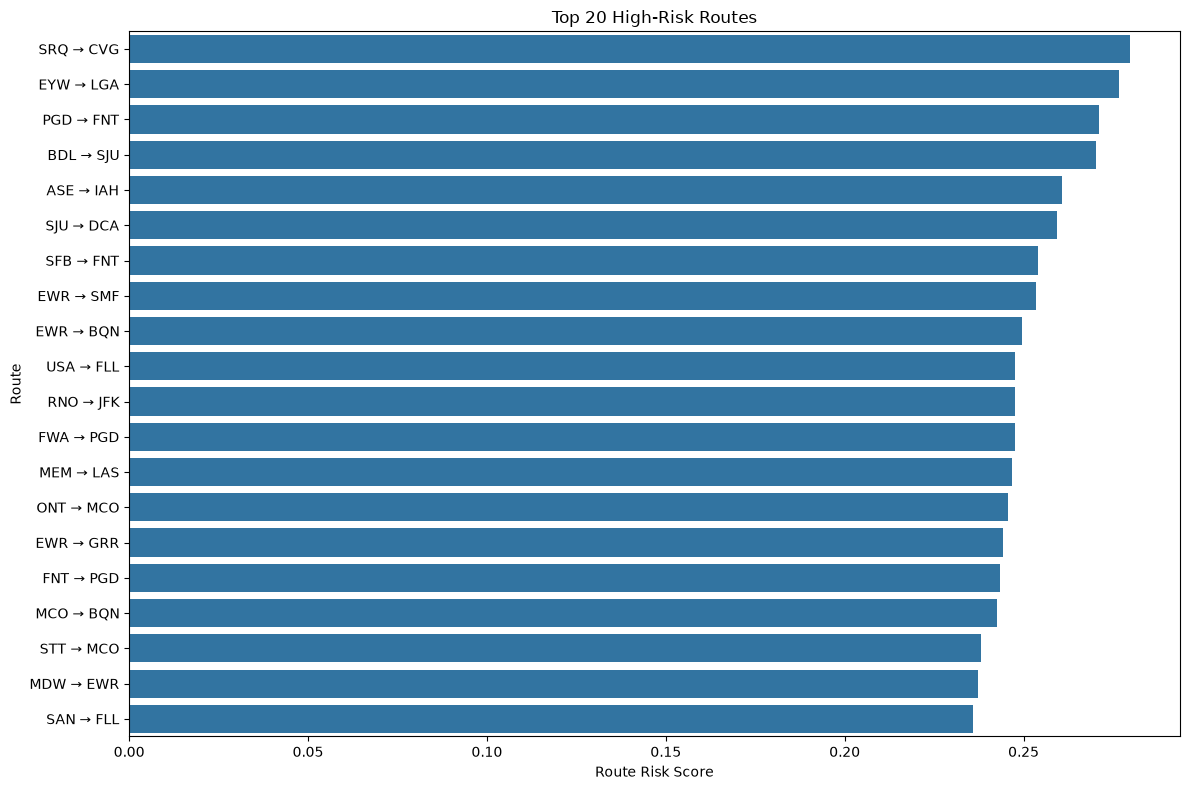

In [169]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=high_risk_routes.head(20),
    x="ROUTE_RISK_SCORE",
    y="ROUTE"
)

plt.title("Top 20 High-Risk Routes")
plt.xlabel("Route Risk Score")
plt.ylabel("Route")

plt.tight_layout()
plt.show()

## Business Answer — BQ2: Which Airports and Routes Have the Highest Delay Burden?

The analysis shows that delay burden is concentrated across a combination of high-volume airports and specific high-risk routes.

### Airport-Level Findings

Among the high-volume airports, **DFW** has the largest total arrival-delay burden with approximately **1.05 million delay minutes**, based on more than **130,000 flights**. **DEN** and **ORD** also show substantial delay exposure, with approximately **858,837** and **716,684 total arrival-delay minutes**, respectively.

Several airports also show relatively high delayed-flight rates. **MCO** has a delayed-flight rate of approximately **38.74%**, followed by **DEN (38.43%)** and **LAS (38.23%)**. MCO also has an average arrival delay of approximately **9.88 minutes** and a severe-delay rate of **8.51%**.

Other airports such as **EWR, FLL, and MIA** also show relatively high average arrival delays and disruption levels. EWR has an average arrival delay of approximately **8.67 minutes** and a severe-delay rate of **9.13%**, while FLL has an average arrival delay of approximately **8.74 minutes** and a severe-delay rate of **8.28%**.

This indicates that airport delay burden should not be evaluated using a single metric. High flight volume creates a large total delay burden, while high delay and severe-delay rates indicate greater operational reliability concerns. :contentReference[oaicite:1]{index=1}

### Airport Risk Score Findings

The rule-based Airport Risk Score combines:

- Delayed-flight rate
- Severe-delay rate
- Disruption rate

with equal weights after normalization.

The highest observed airport risk scores were:

- **ART:** 0.684
- **OGD:** 0.666
- **HYA:** 0.590
- **ASE:** 0.561
- **HTS:** 0.557

For example, ART had a delayed-flight rate of **42.86%**, severe-delay rate of **14.29%**, and disruption rate of **14.29%**. OGD had the highest delayed-flight rate among these airports at **50.00%** and a disruption rate of **22.22%**. :contentReference[oaicite:2]{index=2}

These results show that smaller airports can also have high operational risk even when their total flight volume is much lower than major hubs. Therefore, airport prioritization should consider both **operational risk rates and traffic volume**.

### Route-Level Findings

The route analysis identified several routes with particularly high average arrival delays.

**RNO → JFK** recorded the highest average arrival delay at approximately **47.41 minutes**, with a severe-delay rate of **17.82%**.

Other routes with high average arrival delays included:

- **ABQ → JFK:** 40.10 minutes
- **ACK → LGA:** 38.88 minutes
- **ASE → ORD:** 38.54 minutes
- **BDL → SJU:** 37.04 minutes
- **ONT → JFK:** 36.38 minutes
- **IAD → SHD:** 34.97 minutes
- **SJU → DCA:** 33.24 minutes
- **ASE → DFW:** 33.20 minutes
- **CHO → ORD:** 33.00 minutes

Several of these routes also have high severe-delay or disruption rates, indicating that the issue is not limited to average delay alone. :contentReference[oaicite:3]{index=3}

### High-Risk Route Findings

Using the rule-based Route Risk Score based on:

- Delayed-flight rate
- Severe-delay rate
- Disruption rate

the highest-risk routes in the analyzed output were:

1. **SRQ → CVG** — Risk Score: 0.280
2. **EYW → LGA** — Risk Score: 0.277
3. **PGD → FNT** — Risk Score: 0.271
4. **BDL → SJU** — Risk Score: 0.270
5. **ASE → IAH** — Risk Score: 0.261

For example, SRQ → CVG had a delayed-flight rate of **61.61%** and severe-delay rate of **18.75%**. BDL → SJU had a delayed-flight rate of **59.93%**, severe-delay rate of **18.89%**, and an average arrival delay of approximately **37.04 minutes**.

ASE → IAH had a lower delayed-flight rate than the first few routes at **48.70%**, but its disruption rate was relatively high at **10.87%**, demonstrating why the combined risk score is useful for identifying different types of operational exposure. :contentReference[oaicite:4]{index=4}

### Management Interpretation

The analysis suggests that airport and route improvement should be approached using two complementary perspectives:

1. **High-volume airports** such as DFW, DEN, and ORD generate a large absolute delay burden because of their large flight volumes.
2. **High-risk airports and routes** can have substantially higher delay, severe-delay, or disruption rates even when their traffic volume is smaller.

Therefore, operational improvement priorities should consider both **delay exposure** and **delay intensity** rather than relying only on total delay minutes.

The rule-based Airport Risk Score and Route Risk Score provide a transparent way to identify locations and routes requiring further operational investigation. These scores are analytical prioritization tools created for this project and should not be interpreted as universal measures of airport or route quality.

## BQ3 — What are the major contributors to flight delays?

### Objective

Identify the major causes of flight delays and quantify their contribution to total delay minutes.

The analysis focuses on five operational delay causes:

- Carrier Delay
- Weather Delay
- NAS Delay
- Security Delay
- Late Aircraft Delay

The objective is to understand which causes contribute the greatest amount of delay and identify potential operational bottlenecks.

In [170]:
delay_causes = [
    "DELAY_DUE_CARRIER",
    "DELAY_DUE_WEATHER",
    "DELAY_DUE_NAS",
    "DELAY_DUE_SECURITY",
    "DELAY_DUE_LATE_AIRCRAFT"
]

delay_cause_totals = (
    cleaned_df[delay_causes]
    .sum()
    .reset_index()
)

delay_cause_totals.columns = ["DELAY_CAUSE", "TOTAL_DELAY_MINUTES"]

delay_cause_totals

,DELAY_CAUSE,TOTAL_DELAY_MINUTES
0,DELAY_DUE_CARRIER,13217960.0
1,DELAY_DUE_WEATHER,2127583.0
2,DELAY_DUE_NAS,7028161.0
3,DELAY_DUE_SECURITY,77907.0
4,DELAY_DUE_LATE_AIRCRAFT,13598175.0


In [171]:
total_cause_delay = delay_cause_totals["TOTAL_DELAY_MINUTES"].sum()

delay_cause_totals["CONTRIBUTION_PERCENT"] = (
    delay_cause_totals["TOTAL_DELAY_MINUTES"]
    / total_cause_delay
    * 100
)

delay_cause_totals = delay_cause_totals.sort_values(
    "TOTAL_DELAY_MINUTES",
    ascending=False
)

delay_cause_totals

,DELAY_CAUSE,TOTAL_DELAY_MINUTES,CONTRIBUTION_PERCENT
4,DELAY_DUE_LATE_AIRCRAFT,13598175.0,37.720543
0,DELAY_DUE_CARRIER,13217960.0,36.665849
2,DELAY_DUE_NAS,7028161.0,19.495708
1,DELAY_DUE_WEATHER,2127583.0,5.901791
3,DELAY_DUE_SECURITY,77907.0,0.216109


In [172]:
cause_name_map = {
    "DELAY_DUE_CARRIER": "Carrier Delay",
    "DELAY_DUE_WEATHER": "Weather Delay",
    "DELAY_DUE_NAS": "NAS Delay",
    "DELAY_DUE_SECURITY": "Security Delay",
    "DELAY_DUE_LATE_AIRCRAFT": "Late Aircraft Delay"
}

delay_cause_totals["DELAY_CAUSE"] = (
    delay_cause_totals["DELAY_CAUSE"]
    .map(cause_name_map)
)

delay_cause_totals

,DELAY_CAUSE,TOTAL_DELAY_MINUTES,CONTRIBUTION_PERCENT
4,Late Aircraft Delay,13598175.0,37.720543
0,Carrier Delay,13217960.0,36.665849
2,NAS Delay,7028161.0,19.495708
1,Weather Delay,2127583.0,5.901791
3,Security Delay,77907.0,0.216109


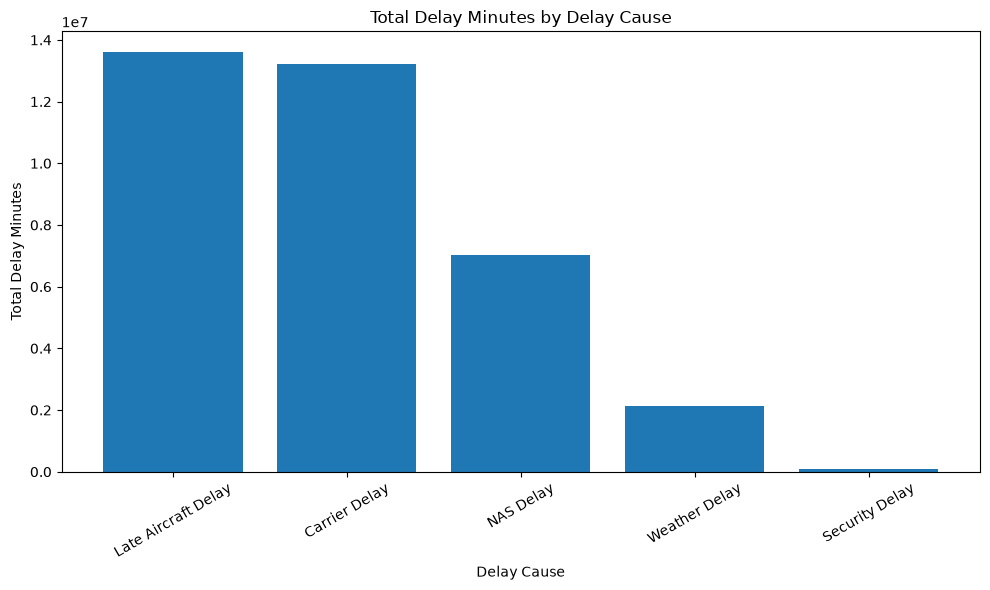

In [173]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    delay_cause_totals["DELAY_CAUSE"],
    delay_cause_totals["TOTAL_DELAY_MINUTES"]
)

plt.title("Total Delay Minutes by Delay Cause")
plt.xlabel("Delay Cause")
plt.ylabel("Total Delay Minutes")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

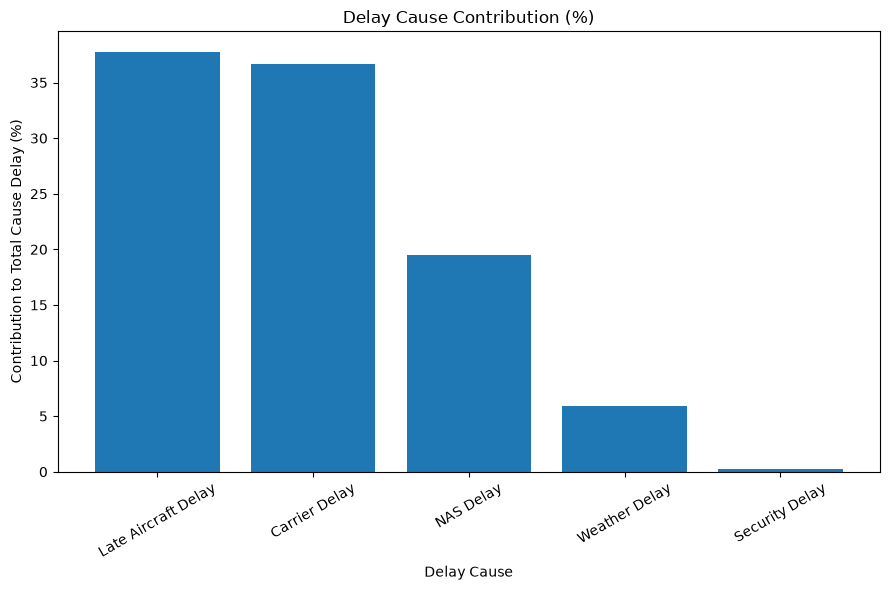

In [174]:
plt.figure(figsize=(9, 6))

plt.bar(
    delay_cause_totals["DELAY_CAUSE"],
    delay_cause_totals["CONTRIBUTION_PERCENT"]
)

plt.title("Delay Cause Contribution (%)")
plt.xlabel("Delay Cause")
plt.ylabel("Contribution to Total Cause Delay (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [175]:
airline_delay_causes = (
    cleaned_df
    .groupby("AIRLINE")[delay_causes]
    .sum()
    .reset_index()
)

airline_delay_causes

,AIRLINE,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT
0,Alaska Airlines Inc.,274241.0,35449.0,268441.0,5197.0,314498.0
1,Allegiant Air,299695.0,71025.0,178073.0,3085.0,405593.0
2,American Airlines Inc.,2004811.0,287614.0,926715.0,12659.0,2290610.0
3,Delta Air Lines Inc.,1758471.0,213070.0,790529.0,6165.0,1048947.0
4,Endeavor Air Inc.,352619.0,75059.0,260884.0,293.0,384290.0
5,Envoy Air,321918.0,145891.0,321533.0,2726.0,471660.0
6,ExpressJet Airlines LLC d/b/a aha!,99441.0,15776.0,121165.0,0.0,91733.0
7,Frontier Airlines Inc.,367576.0,26493.0,263251.0,0.0,536013.0
8,Hawaiian Airlines Inc.,133772.0,7098.0,7299.0,940.0,88369.0
9,Horizon Air,55874.0,9697.0,25839.0,563.0,59131.0


In [176]:
airline_delay_causes_pct = airline_delay_causes.copy()

airline_delay_causes_pct[delay_causes] = (
    airline_delay_causes_pct[delay_causes]
    .div(
        airline_delay_causes_pct[delay_causes].sum(axis=1),
        axis=0
    )
    * 100
)

airline_delay_causes_pct

,AIRLINE,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT
0,Alaska Airlines Inc.,30.545005,3.948315,29.899000,0.578843,35.028836
1,Allegiant Air,31.300687,7.417979,18.598266,0.322203,42.360865
2,American Airlines Inc.,36.303197,5.208126,16.780992,0.229230,41.478456
3,Delta Air Lines Inc.,46.067256,5.581866,20.709754,0.161507,27.479617
4,Endeavor Air Inc.,32.858467,6.994302,24.310228,0.027303,35.809700
5,Envoy Air,25.473678,11.544494,25.443212,0.215711,37.322905
6,ExpressJet Airlines LLC d/b/a aha!,30.306752,4.808070,36.927602,0.000000,27.957576
7,Frontier Airlines Inc.,30.802467,2.220084,22.060146,0.000000,44.917303
8,Hawaiian Airlines Inc.,56.330271,2.988908,3.073548,0.395826,37.211447
9,Horizon Air,36.977181,6.417434,17.100143,0.372591,39.132650


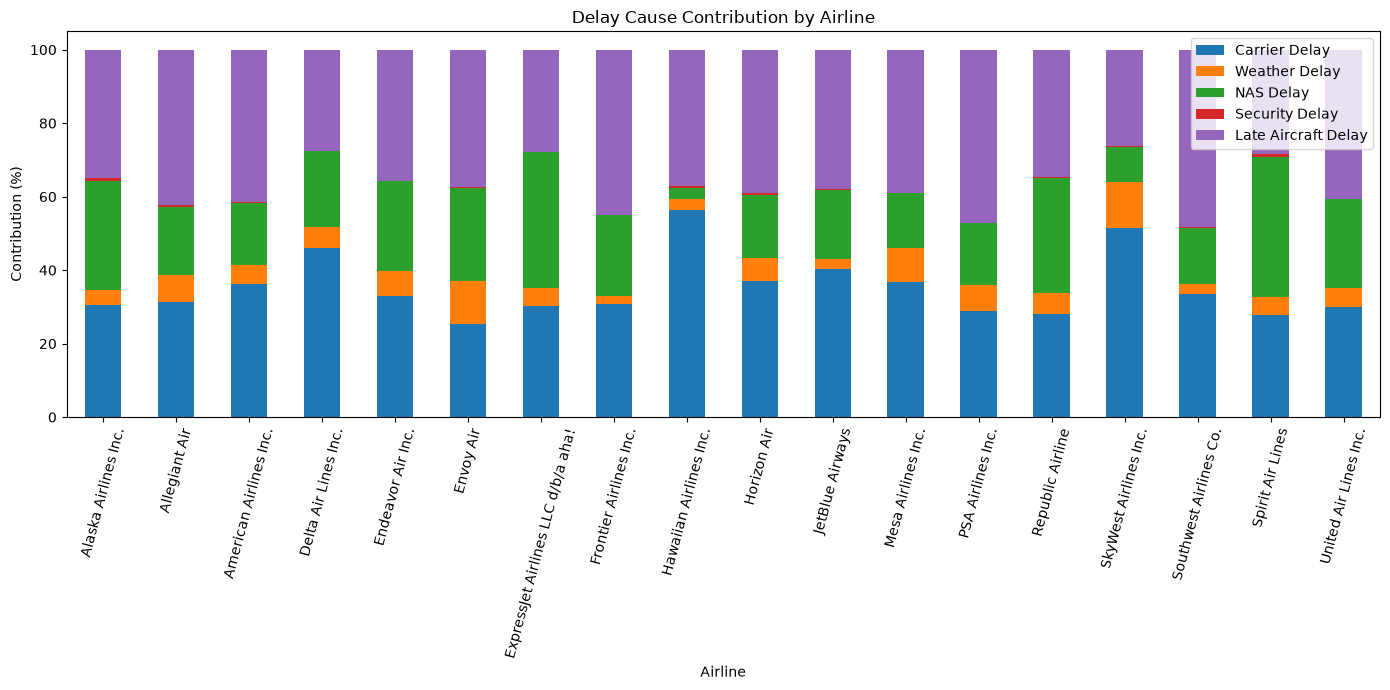

In [177]:
airline_delay_causes_pct_plot = (
    airline_delay_causes_pct
    .set_index("AIRLINE")
)

airline_delay_causes_pct_plot.columns = [
    cause_name_map[col]
    for col in airline_delay_causes_pct_plot.columns
]

airline_delay_causes_pct_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("Delay Cause Contribution by Airline")
plt.xlabel("Airline")
plt.ylabel("Contribution (%)")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

In [178]:
airport_delay_causes = (
    cleaned_df
    .groupby("ORIGIN")[delay_causes]
    .sum()
    .reset_index()
)

airport_delay_causes

,ORIGIN,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT
0,ABE,14109.0,2349.0,3995.0,43.0,6161.0
1,ABI,3224.0,2446.0,2118.0,87.0,3783.0
2,ABQ,38104.0,6035.0,15725.0,51.0,38208.0
3,ABR,4462.0,1001.0,156.0,18.0,312.0
4,ABY,1234.0,188.0,280.0,0.0,1245.0
...,...,...,...,...,...,...
375,XNA,21648.0,7745.0,17653.0,69.0,24434.0
376,XWA,5938.0,2700.0,809.0,16.0,761.0
377,YAK,299.0,103.0,305.0,0.0,2289.0
378,YKM,525.0,32.0,140.0,0.0,213.0


In [179]:
airport_delay_causes_high_volume = (
    airport_delay_causes
    .merge(
        airport_kpi[["ORIGIN", "TOTAL_FLIGHTS"]],
        on="ORIGIN",
        how="left"
    )
)

airport_delay_causes_high_volume = (
    airport_delay_causes_high_volume[
        airport_delay_causes_high_volume["TOTAL_FLIGHTS"] >= 10000
    ]
)

airport_delay_causes_high_volume

,ORIGIN,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT,TOTAL_FLIGHTS
23,ATL,654252.0,89039.0,283676.0,3024.0,387232.0,153556
26,AUS,132825.0,14110.0,69305.0,1188.0,174226.0,32671
31,BDL,42218.0,3788.0,29443.0,265.0,54400.0,10553
47,BNA,123975.0,14254.0,87731.0,728.0,184394.0,37478
48,BOI,38002.0,5656.0,17660.0,1185.0,27597.0,10097
49,BOS,285594.0,32434.0,188249.0,714.0,252231.0,55394
60,BUR,31048.0,2828.0,22711.0,158.0,55284.0,12211
61,BWI,195239.0,16656.0,91230.0,1658.0,177847.0,41043
71,CHS,37051.0,5242.0,28912.0,79.0,52225.0,10622
75,CLE,72806.0,5967.0,55771.0,209.0,81416.0,17966


In [180]:
airline_cause_columns = [
    col for col in airline_delay_causes.columns
    if col != "AIRLINE"
]

airline_delay_causes["DOMINANT_DELAY_CAUSE"] = (
    airline_delay_causes[airline_cause_columns]
    .idxmax(axis=1)
)

airline_delay_causes[
    ["AIRLINE", "DOMINANT_DELAY_CAUSE"]
]

,AIRLINE,DOMINANT_DELAY_CAUSE
0,Alaska Airlines Inc.,DELAY_DUE_LATE_AIRCRAFT
1,Allegiant Air,DELAY_DUE_LATE_AIRCRAFT
2,American Airlines Inc.,DELAY_DUE_LATE_AIRCRAFT
3,Delta Air Lines Inc.,DELAY_DUE_CARRIER
4,Endeavor Air Inc.,DELAY_DUE_LATE_AIRCRAFT
5,Envoy Air,DELAY_DUE_LATE_AIRCRAFT
6,ExpressJet Airlines LLC d/b/a aha!,DELAY_DUE_NAS
7,Frontier Airlines Inc.,DELAY_DUE_LATE_AIRCRAFT
8,Hawaiian Airlines Inc.,DELAY_DUE_CARRIER
9,Horizon Air,DELAY_DUE_LATE_AIRCRAFT


In [181]:
airline_delay_causes["DOMINANT_DELAY_CAUSE"] = (
    airline_delay_causes["DOMINANT_DELAY_CAUSE"]
    .map(cause_name_map)
)

airline_delay_causes[
    ["AIRLINE", "DOMINANT_DELAY_CAUSE"]
]

,AIRLINE,DOMINANT_DELAY_CAUSE
0,Alaska Airlines Inc.,Late Aircraft Delay
1,Allegiant Air,Late Aircraft Delay
2,American Airlines Inc.,Late Aircraft Delay
3,Delta Air Lines Inc.,Carrier Delay
4,Endeavor Air Inc.,Late Aircraft Delay
5,Envoy Air,Late Aircraft Delay
6,ExpressJet Airlines LLC d/b/a aha!,NAS Delay
7,Frontier Airlines Inc.,Late Aircraft Delay
8,Hawaiian Airlines Inc.,Carrier Delay
9,Horizon Air,Late Aircraft Delay


In [182]:
airport_cause_columns = [
    col for col in airport_delay_causes.columns
    if col != "ORIGIN"
]

airport_delay_causes["DOMINANT_DELAY_CAUSE"] = (
    airport_delay_causes[airport_cause_columns]
    .idxmax(axis=1)
)

airport_delay_causes["DOMINANT_DELAY_CAUSE"] = (
    airport_delay_causes["DOMINANT_DELAY_CAUSE"]
    .map(cause_name_map)
)

airport_delay_causes[
    ["ORIGIN", "DOMINANT_DELAY_CAUSE"]
]

,ORIGIN,DOMINANT_DELAY_CAUSE
0,ABE,Carrier Delay
1,ABI,Late Aircraft Delay
2,ABQ,Late Aircraft Delay
3,ABR,Carrier Delay
4,ABY,Late Aircraft Delay
...,...,...
375,XNA,Late Aircraft Delay
376,XWA,Carrier Delay
377,YAK,Late Aircraft Delay
378,YKM,Carrier Delay


In [183]:
airport_delay_causes_pct = airport_delay_causes_high_volume.copy()

airport_delay_causes_pct[delay_causes] = (
    airport_delay_causes_pct[delay_causes]
    .div(
        airport_delay_causes_pct[delay_causes].sum(axis=1),
        axis=0
    )
    * 100
)

airport_delay_causes_pct

,ORIGIN,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT,TOTAL_FLIGHTS
23,ATL,46.164365,6.282639,20.016328,0.213375,27.323294,153556
26,AUS,33.913863,3.602670,17.695466,0.303329,44.484673,32671
31,BDL,32.446931,2.911293,22.628618,0.203668,41.809490,10553
47,BNA,30.158217,3.467435,21.341484,0.177094,44.855771,37478
48,BOI,42.177580,6.277469,19.600444,1.315205,30.629301,10097
49,BOS,37.616665,4.272005,24.794988,0.094044,33.222299,55394
60,BUR,27.714253,2.524346,20.272429,0.141035,49.347937,12211
61,BWI,40.453142,3.451091,18.902679,0.343534,36.849553,41043
71,CHS,29.998624,4.244225,23.408820,0.063963,42.284368,10622
75,CLE,33.680130,2.760340,25.799722,0.096684,37.663125,17966


In [184]:
delay_cause_totals

,DELAY_CAUSE,TOTAL_DELAY_MINUTES,CONTRIBUTION_PERCENT
4,Late Aircraft Delay,13598175.0,37.720543
0,Carrier Delay,13217960.0,36.665849
2,NAS Delay,7028161.0,19.495708
1,Weather Delay,2127583.0,5.901791
3,Security Delay,77907.0,0.216109


In [185]:
airline_delay_causes

,AIRLINE,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT,DOMINANT_DELAY_CAUSE
0,Alaska Airlines Inc.,274241.0,35449.0,268441.0,5197.0,314498.0,Late Aircraft Delay
1,Allegiant Air,299695.0,71025.0,178073.0,3085.0,405593.0,Late Aircraft Delay
2,American Airlines Inc.,2004811.0,287614.0,926715.0,12659.0,2290610.0,Late Aircraft Delay
3,Delta Air Lines Inc.,1758471.0,213070.0,790529.0,6165.0,1048947.0,Carrier Delay
4,Endeavor Air Inc.,352619.0,75059.0,260884.0,293.0,384290.0,Late Aircraft Delay
5,Envoy Air,321918.0,145891.0,321533.0,2726.0,471660.0,Late Aircraft Delay
6,ExpressJet Airlines LLC d/b/a aha!,99441.0,15776.0,121165.0,0.0,91733.0,NAS Delay
7,Frontier Airlines Inc.,367576.0,26493.0,263251.0,0.0,536013.0,Late Aircraft Delay
8,Hawaiian Airlines Inc.,133772.0,7098.0,7299.0,940.0,88369.0,Carrier Delay
9,Horizon Air,55874.0,9697.0,25839.0,563.0,59131.0,Late Aircraft Delay


In [186]:
airport_delay_causes_pct

,ORIGIN,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT,TOTAL_FLIGHTS
23,ATL,46.164365,6.282639,20.016328,0.213375,27.323294,153556
26,AUS,33.913863,3.602670,17.695466,0.303329,44.484673,32671
31,BDL,32.446931,2.911293,22.628618,0.203668,41.809490,10553
47,BNA,30.158217,3.467435,21.341484,0.177094,44.855771,37478
48,BOI,42.177580,6.277469,19.600444,1.315205,30.629301,10097
49,BOS,37.616665,4.272005,24.794988,0.094044,33.222299,55394
60,BUR,27.714253,2.524346,20.272429,0.141035,49.347937,12211
61,BWI,40.453142,3.451091,18.902679,0.343534,36.849553,41043
71,CHS,29.998624,4.244225,23.408820,0.063963,42.284368,10622
75,CLE,33.680130,2.760340,25.799722,0.096684,37.663125,17966


In [187]:
airport_delay_causes_high_volume

,ORIGIN,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT,TOTAL_FLIGHTS
23,ATL,654252.0,89039.0,283676.0,3024.0,387232.0,153556
26,AUS,132825.0,14110.0,69305.0,1188.0,174226.0,32671
31,BDL,42218.0,3788.0,29443.0,265.0,54400.0,10553
47,BNA,123975.0,14254.0,87731.0,728.0,184394.0,37478
48,BOI,38002.0,5656.0,17660.0,1185.0,27597.0,10097
49,BOS,285594.0,32434.0,188249.0,714.0,252231.0,55394
60,BUR,31048.0,2828.0,22711.0,158.0,55284.0,12211
61,BWI,195239.0,16656.0,91230.0,1658.0,177847.0,41043
71,CHS,37051.0,5242.0,28912.0,79.0,52225.0,10622
75,CLE,72806.0,5967.0,55771.0,209.0,81416.0,17966


## Business Answer — BQ3: What Are the Major Contributors to Flight Delays?

The delay-cause analysis shows that **Late Aircraft Delay and Carrier Delay are the two largest contributors to total delay minutes** in the dataset.

### Overall Delay-Cause Findings

Across all flights, the total delay-cause contribution was:

| Delay Cause | Total Delay Minutes | Contribution |
|---|---:|---:|
| Late Aircraft Delay | 13,598,175 | 37.72% |
| Carrier Delay | 13,217,960 | 36.67% |
| NAS Delay | 7,028,161 | 19.50% |
| Weather Delay | 2,127,583 | 5.90% |
| Security Delay | 77,907 | 0.22% |

Late Aircraft Delay accounts for approximately **37.72%** of all cause-attributed delay minutes, while Carrier Delay contributes approximately **36.67%**. Together, these two causes account for approximately **74.39%** of total delay-cause minutes.

NAS Delay is the third-largest contributor at approximately **19.50%**, while Weather Delay contributes **5.90%**. Security Delay represents only **0.22%** of the total. :contentReference[oaicite:1]{index=1}

### Airline-Level Findings

The dominant delay cause varies across airlines.

For most airlines, **Late Aircraft Delay** is the dominant cause. This includes Alaska Airlines, Allegiant Air, American Airlines, Endeavor Air, Envoy Air, Frontier Airlines, Horizon Air, Mesa Airlines, PSA Airlines, Republic Airline, Southwest Airlines, and United Airlines.

Several airlines have **Carrier Delay** as their dominant cause, including Delta Air Lines, Hawaiian Airlines, JetBlue Airways, and SkyWest Airlines.

Two airlines in the analysis show **NAS Delay** as their dominant cause:

- ExpressJet Airlines LLC d/b/a aha!
- Spirit Air Lines

The contribution percentages also show meaningful differences between airlines. For example, Southwest Airlines has approximately **48.21%** of its cause-attributed delay minutes associated with Late Aircraft Delay, while PSA Airlines has approximately **47.06%** from the same cause.

SkyWest Airlines shows a different pattern, with approximately **51.60%** of its cause-attributed delay minutes associated with Carrier Delay.

Spirit Air Lines has approximately **38.11%** associated with NAS Delay, making NAS its largest delay contributor. :contentReference[oaicite:2]{index=2}

### Airport-Level Findings

Airport-level analysis shows that delay causes also vary considerably by origin airport.

For example:

- **ATL:** Carrier Delay represents approximately 46.16%, while Late Aircraft Delay represents 27.32%.
- **DFW:** Carrier Delay represents approximately 45.81% and Late Aircraft Delay approximately 28.98%.
- **DEN:** Carrier Delay represents approximately 40.30% and Late Aircraft Delay approximately 38.18%.
- **ORD:** Carrier Delay represents approximately 32.07% and Late Aircraft Delay approximately 38.89%.
- **CLT:** Carrier Delay represents approximately 36.84% and Late Aircraft Delay approximately 42.11%.
- **BUR:** Late Aircraft Delay represents approximately 49.35%, making it the largest contributor among the listed causes.
- **CVG:** Late Aircraft Delay represents approximately 35.01%, while NAS Delay contributes approximately 28.42%.

These differences indicate that airports do not have identical delay profiles. Some airports have a larger carrier-related component, while others show a greater contribution from aircraft arriving late from previous operations or from NAS-related factors. 

### Operational Bottleneck Interpretation

The results suggest three major operational patterns:

**1. Late aircraft propagation is a major source of disruption.**

Because Late Aircraft Delay contributes **37.72%** of total cause-attributed delay minutes, downstream flights can inherit delays from earlier flights. This indicates that schedule recovery, aircraft rotation management, turnaround processes, and network connectivity are important areas for further investigation.

**2. Carrier-related delays are almost equally important.**

Carrier Delay contributes **36.67%** of total delay-cause minutes. This indicates that airline-controlled operational factors represent a major component of the observed delay burden.

**3. NAS-related delays form another substantial source.**

NAS Delay contributes **19.50%** overall, but its importance differs by airline and airport. Spirit Air Lines, for example, has NAS Delay as its dominant cause, while several airports also show relatively large NAS contributions.

### Management Finding

The analysis indicates that delay-reduction efforts should not focus on a single cause.

The largest opportunity areas identified from the dataset are:

- **Late-aircraft propagation**
- **Carrier-related operational delays**
- **NAS-related constraints**

Weather is an important but smaller contributor to total delay minutes in this dataset, while security delays represent a very small share of total cause-attributed delay.

Because the dominant cause differs across airlines and airports, operational improvement should be targeted according to the specific delay profile of each airline or airport rather than applying the same intervention everywhere.

### Important Analytical Limitation

The delay-cause percentages represent the distribution of **cause-attributed delay minutes**, not the percentage of all flights that were delayed.

A single flight can also have multiple delay-cause fields recorded, so these percentages should be interpreted as a breakdown of recorded delay minutes rather than mutually exclusive flight categories.

Therefore, the results identify **where the delay burden comes from**, but they do not by themselves establish that a particular cause is the sole underlying root cause of an individual delay.

# Business Question 4

## Which periods of the year show the highest operational risk?

### Objective

Analyze flight operations across years, months, weekdays, and seasons
to identify periods with higher delay and operational disruption.

The analysis uses average arrival delay, delayed-flight rate,
cancellation rate, diversion rate, and flight volume to identify
recurring high-risk periods.

In [188]:
yearly_kpi = (
    cleaned_df.groupby("YEAR")
    .agg(
        TOTAL_FLIGHTS=("FL_DATE", "count"),
        AVG_DEP_DELAY=("DEP_DELAY", "mean"),
        AVG_ARR_DELAY=("ARR_DELAY", "mean"),
        DELAYED_FLIGHT_RATE=("ARR_DELAY", lambda x: (x > 0).mean()),
        CANCELLATION_RATE=("CANCELLED", "mean"),
        DIVERSION_RATE=("DIVERTED", "mean")
    )
    .reset_index()
)

yearly_kpi

,YEAR,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
0,2019,757673,10.812446,5.309075,0.336705,0.017942,0.002617
1,2020,479350,2.030849,-5.010315,0.204656,0.059992,0.001606
2,2021,611633,9.389651,3.096894,0.320302,0.017219,0.002276
3,2022,687860,12.502406,6.912789,0.362367,0.026819,0.002399
4,2023,463484,14.470020,9.365672,0.387862,0.016848,0.002721


In [189]:
rate_columns = [
    "DELAYED_FLIGHT_RATE",
    "CANCELLATION_RATE",
    "DIVERSION_RATE"
]

yearly_kpi[rate_columns] = yearly_kpi[rate_columns] * 100

yearly_kpi

,YEAR,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
0,2019,757673,10.812446,5.309075,33.670462,1.794178,0.261722
1,2020,479350,2.030849,-5.010315,20.465631,5.999166,0.160634
2,2021,611633,9.389651,3.096894,32.030155,1.721948,0.227587
3,2022,687860,12.502406,6.912789,36.236734,2.681941,0.239874
4,2023,463484,14.470020,9.365672,38.786236,1.684848,0.272070


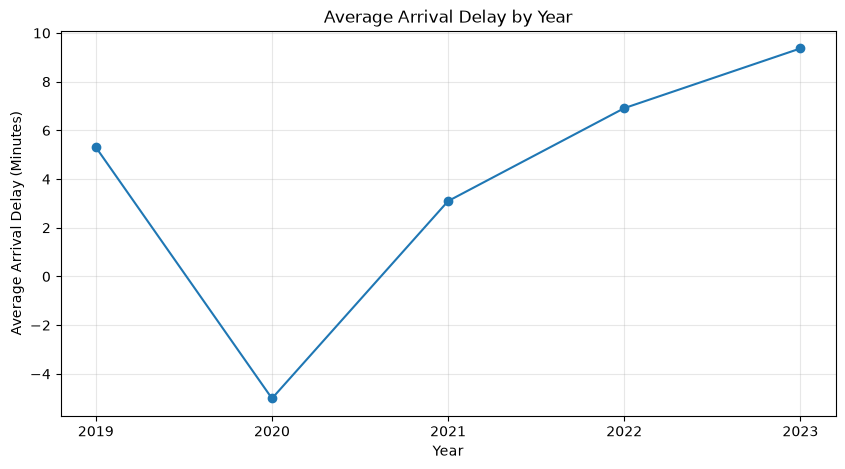

In [190]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_kpi["YEAR"],
    yearly_kpi["AVG_ARR_DELAY"],
    marker="o"
)

plt.title("Average Arrival Delay by Year")
plt.xlabel("Year")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(yearly_kpi["YEAR"])
plt.grid(True, alpha=0.3)

plt.show()

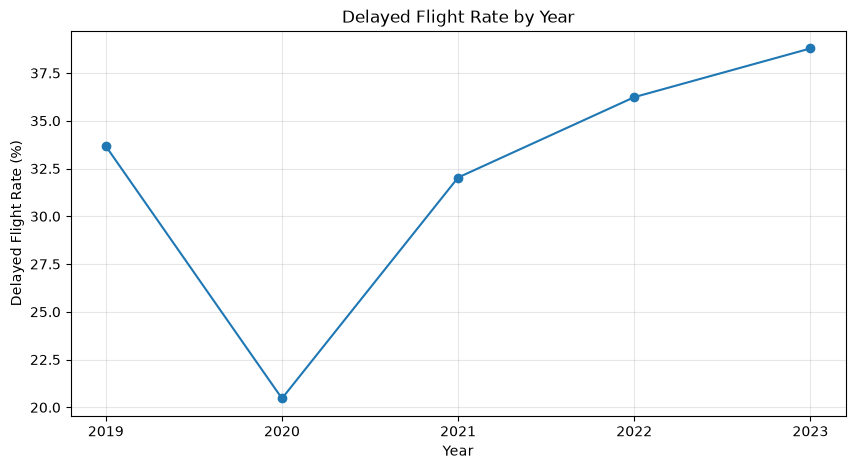

In [191]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_kpi["YEAR"],
    yearly_kpi["DELAYED_FLIGHT_RATE"],
    marker="o"
)

plt.title("Delayed Flight Rate by Year")
plt.xlabel("Year")
plt.ylabel("Delayed Flight Rate (%)")
plt.xticks(yearly_kpi["YEAR"])
plt.grid(True, alpha=0.3)

plt.show()

In [192]:
monthly_kpi = (
    cleaned_df.groupby("MONTH")
    .agg(
        TOTAL_FLIGHTS=("FL_DATE", "count"),
        AVG_DEP_DELAY=("DEP_DELAY", "mean"),
        AVG_ARR_DELAY=("ARR_DELAY", "mean"),
        DELAYED_FLIGHT_RATE=("ARR_DELAY", lambda x: (x > 0).mean()),
        CANCELLATION_RATE=("CANCELLED", "mean"),
        DIVERSION_RATE=("DIVERTED", "mean")
    )
    .reset_index()
)

monthly_kpi[rate_columns] = monthly_kpi[rate_columns] * 100

monthly_kpi

,MONTH,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
0,1,268702,8.718996,2.190728,30.568064,2.734256,0.212131
1,2,248497,9.823191,3.712646,32.398781,2.892590,0.214490
2,3,293099,8.320393,2.255956,30.431356,5.029017,0.182191
3,4,253917,9.597162,3.539976,30.454834,6.851058,0.209123
4,5,252530,9.425539,3.359411,31.916208,1.719004,0.260563
5,6,261136,15.047865,10.061753,38.766773,2.012744,0.337755
6,7,284968,14.666483,9.491415,37.082058,1.788622,0.336880
7,8,287104,11.846190,6.453106,34.241251,1.986040,0.278296
8,9,206928,5.776012,-0.512181,26.747951,1.283055,0.189438
9,10,216790,7.330811,1.424036,30.534619,1.084921,0.176669


In [193]:
monthly_kpi.sort_values(
    "AVG_ARR_DELAY",
    ascending=False
)

,MONTH,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
5,6,261136,15.047865,10.061753,38.766773,2.012744,0.337755
6,7,284968,14.666483,9.491415,37.082058,1.788622,0.336880
11,12,215389,12.413276,6.672484,36.596112,2.506163,0.225638
7,8,287104,11.846190,6.453106,34.241251,1.986040,0.278296
1,2,248497,9.823191,3.712646,32.398781,2.892590,0.214490
3,4,253917,9.597162,3.539976,30.454834,6.851058,0.209123
4,5,252530,9.425539,3.359411,31.916208,1.719004,0.260563
2,3,293099,8.320393,2.255956,30.431356,5.029017,0.182191
0,1,268702,8.718996,2.190728,30.568064,2.734256,0.212131
9,10,216790,7.330811,1.424036,30.534619,1.084921,0.176669


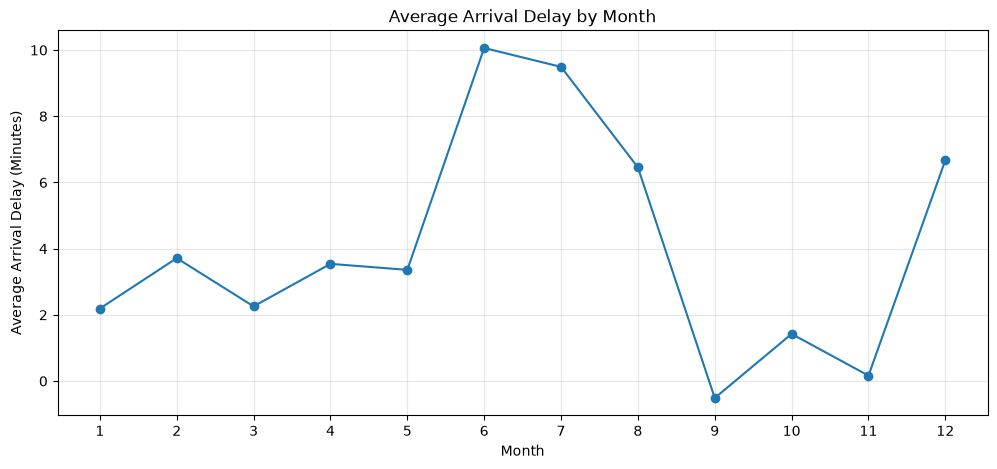

In [194]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_kpi["MONTH"],
    monthly_kpi["AVG_ARR_DELAY"],
    marker="o"
)

plt.title("Average Arrival Delay by Month")
plt.xlabel("Month")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)

plt.show()

In [195]:
cleaned_df["DAY_OF_WEEK"].value_counts().sort_index()

DAY_OF_WEEK
Friday       446292
Monday       446600
Saturday     384223
Sunday       436561
Thursday     446925
Tuesday      416562
Wednesday    422837
Name: count, dtype: int64

In [196]:
day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

In [197]:
weekday_kpi = (
    cleaned_df.groupby("DAY_OF_WEEK")
    .agg(
        TOTAL_FLIGHTS=("FL_DATE", "count"),
        AVG_DEP_DELAY=("DEP_DELAY", "mean"),
        AVG_ARR_DELAY=("ARR_DELAY", "mean"),
        DELAYED_FLIGHT_RATE=("ARR_DELAY", lambda x: (x > 0).mean()),
        CANCELLATION_RATE=("CANCELLED", "mean"),
        DIVERSION_RATE=("DIVERTED", "mean")
    )
    .reset_index()
)

weekday_kpi[rate_columns] = weekday_kpi[rate_columns] * 100

weekday_kpi["DAY_NAME"] = weekday_kpi["DAY_OF_WEEK"].map(day_names)

weekday_kpi

,DAY_OF_WEEK,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE,DAY_NAME
0,Friday,446292,11.388175,5.947104,35.070761,2.600315,0.234600,NaN
1,Monday,446600,10.588799,4.717601,32.759516,2.673309,0.233094,NaN
2,Saturday,384223,10.194353,3.669612,31.280012,2.510261,0.230856,NaN
3,Sunday,436561,11.264496,5.291464,33.692199,2.667668,0.246014,NaN
4,Thursday,446925,10.801696,5.563596,34.315601,2.831571,0.244113,NaN
5,Tuesday,416562,7.991091,1.693007,29.735310,2.471181,0.207412,NaN
6,Wednesday,422837,8.441622,2.632201,30.939109,2.685668,0.248796,NaN


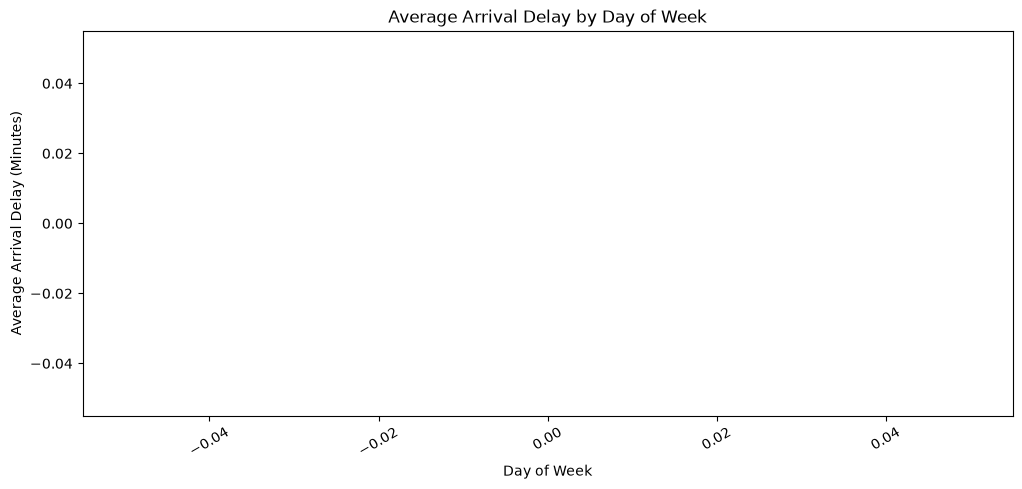

In [198]:
plt.figure(figsize=(12, 5))

plt.bar(
    weekday_kpi["DAY_NAME"],
    weekday_kpi["AVG_ARR_DELAY"]
)

plt.title("Average Arrival Delay by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(rotation=30)

plt.show()

In [199]:
def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Fall"

In [200]:
cleaned_df["SEASON"] = cleaned_df["MONTH"].apply(assign_season)

In [201]:
seasonal_kpi = (
    cleaned_df.groupby("SEASON")
    .agg(
        TOTAL_FLIGHTS=("FL_DATE", "count"),
        AVG_DEP_DELAY=("DEP_DELAY", "mean"),
        AVG_ARR_DELAY=("ARR_DELAY", "mean"),
        DELAYED_FLIGHT_RATE=("ARR_DELAY", lambda x: (x > 0).mean()),
        CANCELLATION_RATE=("CANCELLED", "mean"),
        DIVERSION_RATE=("DIVERTED", "mean")
    )
    .reset_index()
)

seasonal_kpi[rate_columns] = seasonal_kpi[rate_columns] * 100

season_order = ["Winter", "Spring", "Summer", "Fall"]

seasonal_kpi["SEASON"] = pd.Categorical(
    seasonal_kpi["SEASON"],
    categories=season_order,
    ordered=True
)

seasonal_kpi = seasonal_kpi.sort_values("SEASON")

seasonal_kpi

,SEASON,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
3,Winter,732588,10.181431,4.026548,32.961364,2.720902,0.216902
1,Spring,799546,9.075620,3.012714,30.907790,4.562214,0.215497
2,Summer,833208,13.814723,8.623259,36.631189,1.926890,0.316968
0,Fall,634658,6.524951,0.374389,29.045565,1.051748,0.173794


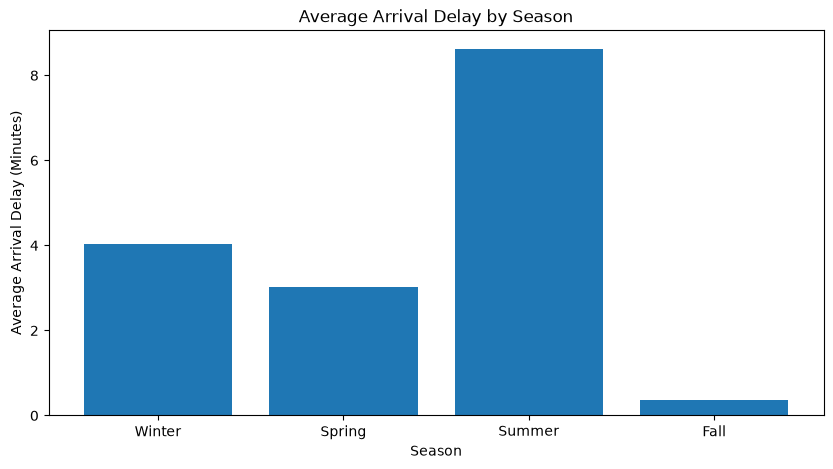

In [202]:
plt.figure(figsize=(10, 5))

plt.bar(
    seasonal_kpi["SEASON"],
    seasonal_kpi["AVG_ARR_DELAY"]
)

plt.title("Average Arrival Delay by Season")
plt.xlabel("Season")
plt.ylabel("Average Arrival Delay (Minutes)")

plt.show()

In [203]:
high_risk_months = monthly_kpi.sort_values(
    [
        "AVG_ARR_DELAY",
        "DELAYED_FLIGHT_RATE"
    ],
    ascending=False
)

high_risk_months[
    [
        "MONTH",
        "TOTAL_FLIGHTS",
        "AVG_ARR_DELAY",
        "DELAYED_FLIGHT_RATE",
        "CANCELLATION_RATE",
        "DIVERSION_RATE"
    ]
].head(5)

,MONTH,TOTAL_FLIGHTS,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
5,6,261136,10.061753,38.766773,2.012744,0.337755
6,7,284968,9.491415,37.082058,1.788622,0.336880
11,12,215389,6.672484,36.596112,2.506163,0.225638
7,8,287104,6.453106,34.241251,1.986040,0.278296
1,2,248497,3.712646,32.398781,2.892590,0.214490


In [204]:
high_risk_weekdays = weekday_kpi.sort_values(
    [
        "AVG_ARR_DELAY",
        "DELAYED_FLIGHT_RATE"
    ],
    ascending=False
)

high_risk_weekdays[
    [
        "DAY_NAME",
        "TOTAL_FLIGHTS",
        "AVG_ARR_DELAY",
        "DELAYED_FLIGHT_RATE",
        "CANCELLATION_RATE",
        "DIVERSION_RATE"
    ]
]

,DAY_NAME,TOTAL_FLIGHTS,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
0,NaN,446292,5.947104,35.070761,2.600315,0.234600
4,NaN,446925,5.563596,34.315601,2.831571,0.244113
3,NaN,436561,5.291464,33.692199,2.667668,0.246014
1,NaN,446600,4.717601,32.759516,2.673309,0.233094
2,NaN,384223,3.669612,31.280012,2.510261,0.230856
6,NaN,422837,2.632201,30.939109,2.685668,0.248796
5,NaN,416562,1.693007,29.735310,2.471181,0.207412


In [205]:
seasonal_kpi.sort_values(
    [
        "AVG_ARR_DELAY",
        "DELAYED_FLIGHT_RATE"
    ],
    ascending=False
)

,SEASON,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
2,Summer,833208,13.814723,8.623259,36.631189,1.926890,0.316968
3,Winter,732588,10.181431,4.026548,32.961364,2.720902,0.216902
1,Spring,799546,9.075620,3.012714,30.907790,4.562214,0.215497
0,Fall,634658,6.524951,0.374389,29.045565,1.051748,0.173794


In [206]:
month_weekday_delay = (
    cleaned_df.groupby(
        ["MONTH", "DAY_OF_WEEK"]
    )["ARR_DELAY"]
    .mean()
    .reset_index()
)

month_weekday_pivot = month_weekday_delay.pivot(
    index="MONTH",
    columns="DAY_OF_WEEK",
    values="ARR_DELAY"
)

month_weekday_pivot

DAY_OF_WEEK,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
MONTH,,,,,,,
1,1.825436,3.687775,1.796534,3.704867,1.805691,-0.066853,2.371817
2,7.412390,2.045504,0.820905,2.740028,9.310658,-0.476955,3.381075
3,5.595295,0.836185,5.055955,4.192423,3.528406,-2.651690,-0.502098
4,5.484592,4.341065,4.521123,6.133407,3.058457,-0.186014,1.109071
5,5.466657,4.069347,1.816158,3.742810,5.305701,1.967453,0.770487
6,10.712098,10.810590,10.356211,12.356389,10.841990,7.037185,8.221665
7,10.976300,9.857991,10.998610,10.578173,10.039475,6.471884,7.186709
8,8.029558,7.035083,3.115136,8.031225,8.783375,4.594197,5.140198
9,2.140188,-0.339536,-4.358992,-0.702529,2.252974,-2.088794,-1.678928


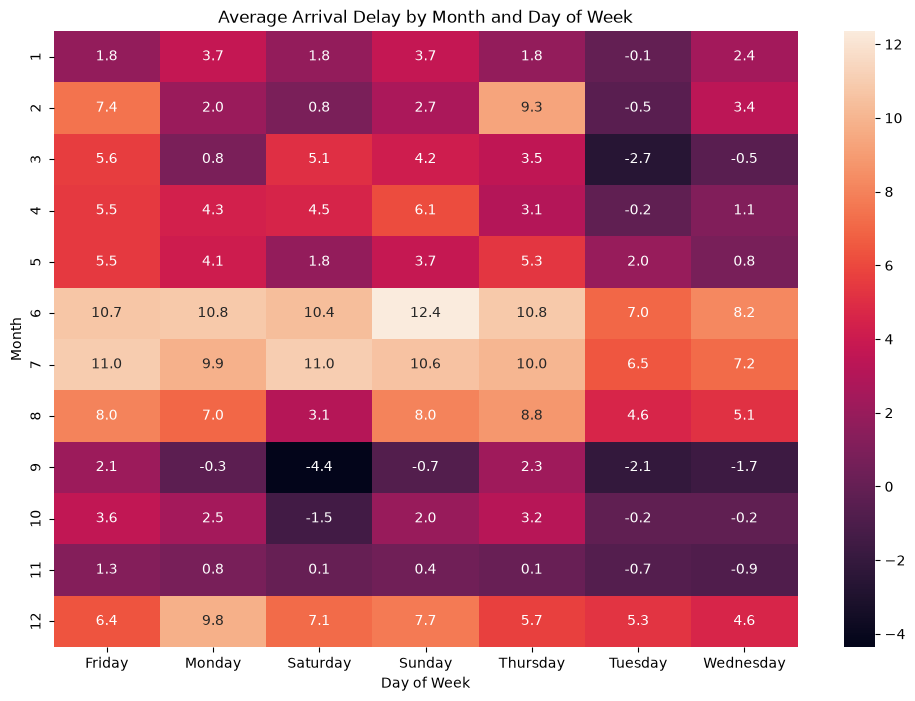

In [207]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    month_weekday_pivot,
    annot=True,
    fmt=".1f"
)

plt.title("Average Arrival Delay by Month and Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Month")

plt.show()

In [208]:
yearly_kpi

,YEAR,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
0,2019,757673,10.812446,5.309075,33.670462,1.794178,0.261722
1,2020,479350,2.030849,-5.010315,20.465631,5.999166,0.160634
2,2021,611633,9.389651,3.096894,32.030155,1.721948,0.227587
3,2022,687860,12.502406,6.912789,36.236734,2.681941,0.239874
4,2023,463484,14.470020,9.365672,38.786236,1.684848,0.272070


In [209]:
monthly_kpi

,MONTH,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
0,1,268702,8.718996,2.190728,30.568064,2.734256,0.212131
1,2,248497,9.823191,3.712646,32.398781,2.892590,0.214490
2,3,293099,8.320393,2.255956,30.431356,5.029017,0.182191
3,4,253917,9.597162,3.539976,30.454834,6.851058,0.209123
4,5,252530,9.425539,3.359411,31.916208,1.719004,0.260563
5,6,261136,15.047865,10.061753,38.766773,2.012744,0.337755
6,7,284968,14.666483,9.491415,37.082058,1.788622,0.336880
7,8,287104,11.846190,6.453106,34.241251,1.986040,0.278296
8,9,206928,5.776012,-0.512181,26.747951,1.283055,0.189438
9,10,216790,7.330811,1.424036,30.534619,1.084921,0.176669


In [210]:
weekday_kpi

,DAY_OF_WEEK,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE,DAY_NAME
0,Friday,446292,11.388175,5.947104,35.070761,2.600315,0.234600,NaN
1,Monday,446600,10.588799,4.717601,32.759516,2.673309,0.233094,NaN
2,Saturday,384223,10.194353,3.669612,31.280012,2.510261,0.230856,NaN
3,Sunday,436561,11.264496,5.291464,33.692199,2.667668,0.246014,NaN
4,Thursday,446925,10.801696,5.563596,34.315601,2.831571,0.244113,NaN
5,Tuesday,416562,7.991091,1.693007,29.735310,2.471181,0.207412,NaN
6,Wednesday,422837,8.441622,2.632201,30.939109,2.685668,0.248796,NaN


In [211]:
seasonal_kpi

,SEASON,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
3,Winter,732588,10.181431,4.026548,32.961364,2.720902,0.216902
1,Spring,799546,9.075620,3.012714,30.907790,4.562214,0.215497
2,Summer,833208,13.814723,8.623259,36.631189,1.926890,0.316968
0,Fall,634658,6.524951,0.374389,29.045565,1.051748,0.173794


In [212]:
high_risk_months.head(5)

,MONTH,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
5,6,261136,15.047865,10.061753,38.766773,2.012744,0.337755
6,7,284968,14.666483,9.491415,37.082058,1.788622,0.336880
11,12,215389,12.413276,6.672484,36.596112,2.506163,0.225638
7,8,287104,11.846190,6.453106,34.241251,1.986040,0.278296
1,2,248497,9.823191,3.712646,32.398781,2.892590,0.214490


## Final Business Answer

### Which periods of the year show the highest operational risk?

The analysis shows that operational delay risk varies across years, months,
weekdays, and seasons.

At the yearly level, **2023** recorded the highest delay exposure, with an
average departure delay of **14.47 minutes**, average arrival delay of
**9.37 minutes**, and a delayed-flight rate of **38.79%**.

At the seasonal level, **Summer** represents the highest delay-risk period.
It recorded the highest average arrival delay (**8.62 minutes**), the highest
delayed-flight rate (**36.63%**), and the highest diversion rate (**0.32%**).
However, Spring recorded the highest cancellation rate (**4.56%**), showing
that different disruption metrics can peak in different seasons.

At the monthly level, **June** was the clearest high-risk month. It had the
highest average arrival delay (**10.06 minutes**), highest delayed-flight
rate (**38.77%**), and highest average departure delay (**15.05 minutes**).
July also showed elevated delay exposure, with a **9.49-minute** average
arrival delay and **37.08%** delayed-flight rate.

At the weekday level, **Friday** recorded the highest average arrival delay
(**5.95 minutes**) and delayed-flight rate (**35.07%**). Thursday also showed
elevated operational disruption, particularly through its **2.83%**
cancellation rate.

Overall, the dataset indicates that **summer, particularly June, represents
the most important recurring period for delay-related operational risk**, with
Friday showing the highest weekday delay exposure. These periods can therefore
be considered priority periods for operational monitoring and resource
planning.

The analysis is descriptive and based on observed historical patterns in this
dataset. It identifies periods with higher operational risk indicators but
does not establish that season or weekday alone causes the delays.

# Business Question 6

## Which airline or airport segments combine high volume with poor reliability?

### Objective

Identify airline and airport segments that handle a high number of flights
while also showing relatively poor operational reliability.

High volume represents operational exposure, while reliability is evaluated
using delay, severe-delay, cancellation, and diversion indicators.

The purpose is to identify segments where operational improvement could have
a larger network-level impact because of their high activity level.

In [213]:
airline_kpi[
    [
        "AIRLINE",
        "TOTAL_FLIGHTS",
        "AVG_ARR_DELAY",
        "SEVERE_DELAY_RATE",
        "CANCELLATION_RATE",
        "DIVERSION_RATE"
    ]
]

,AIRLINE,TOTAL_FLIGHTS,AVG_ARR_DELAY,SEVERE_DELAY_RATE,CANCELLATION_RATE,DIVERSION_RATE
0,Alaska Airlines Inc.,100467,1.097900,4.109807,1.925010,0.237889
1,Allegiant Air,52738,13.284601,8.500512,4.518563,0.333725
2,American Airlines Inc.,383106,6.661229,6.714852,2.846993,0.256065
3,Delta Air Lines Inc.,395239,1.085079,4.386966,1.513515,0.197855
4,Endeavor Air Inc.,112463,-1.258539,4.818474,2.128700,0.196509
5,Envoy Air,121256,3.278914,5.178300,2.996140,0.256482
6,ExpressJet Airlines LLC d/b/a aha!,19082,10.031976,8.264333,5.565454,0.361597
7,Frontier Airlines Inc.,64466,11.100429,9.690379,2.584308,0.136506
8,Hawaiian Airlines Inc.,32114,3.894757,2.478670,1.208196,0.087189
9,Horizon Air,20634,2.376242,3.615392,1.812542,0.111467


In [214]:
airline_volume_threshold = airline_kpi["TOTAL_FLIGHTS"].median()

airline_volume_threshold

np.float64(109756.5)

In [215]:
airline_kpi["VOLUME_SEGMENT"] = np.where(
    airline_kpi["TOTAL_FLIGHTS"] >= airline_volume_threshold,
    "High Volume",
    "Lower Volume"
)

airline_kpi[
    [
        "AIRLINE",
        "TOTAL_FLIGHTS",
        "VOLUME_SEGMENT"
    ]
].sort_values(
    "TOTAL_FLIGHTS",
    ascending=False
)

,AIRLINE,TOTAL_FLIGHTS,VOLUME_SEGMENT
15,Southwest Airlines Co.,576470,High Volume
3,Delta Air Lines Inc.,395239,High Volume
2,American Airlines Inc.,383106,High Volume
14,SkyWest Airlines Inc.,343737,High Volume
17,United Air Lines Inc.,254504,High Volume
13,Republic Airline,143107,High Volume
5,Envoy Air,121256,High Volume
10,JetBlue Airways,112844,High Volume
4,Endeavor Air Inc.,112463,High Volume
12,PSA Airlines Inc.,107050,Lower Volume


The median flight volume is used as a transparent dataset-specific
benchmark to separate higher-volume and lower-volume airlines.

This is an analytical segmentation rule rather than a universal airline
industry threshold.

In [216]:
airline_delay_threshold = airline_kpi["AVG_ARR_DELAY"].median()

airline_severe_threshold = airline_kpi["SEVERE_DELAY_RATE"].median()

airline_cancel_threshold = airline_kpi["CANCELLATION_RATE"].median()

airline_diversion_threshold = airline_kpi["DIVERSION_RATE"].median()

(
    airline_delay_threshold,
    airline_severe_threshold,
    airline_cancel_threshold,
    airline_diversion_threshold
)

(np.float64(3.9759831850628045),
 np.float64(5.907443527834178),
 np.float64(2.638703222050834),
 np.float64(0.24318553792369735))

In [217]:
airline_kpi["HIGH_DELAY"] = (
    airline_kpi["AVG_ARR_DELAY"] > airline_delay_threshold
)

airline_kpi["HIGH_SEVERE_DELAY"] = (
    airline_kpi["SEVERE_DELAY_RATE"] > airline_severe_threshold
)

airline_kpi["HIGH_CANCELLATION"] = (
    airline_kpi["CANCELLATION_RATE"] > airline_cancel_threshold
)

airline_kpi["HIGH_DIVERSION"] = (
    airline_kpi["DIVERSION_RATE"] > airline_diversion_threshold
)

In [218]:
airline_kpi["POOR_RELIABILITY_INDICATORS"] = (
    airline_kpi[
        [
            "HIGH_DELAY",
            "HIGH_SEVERE_DELAY",
            "HIGH_CANCELLATION",
            "HIGH_DIVERSION"
        ]
    ]
    .sum(axis=1)
)

airline_kpi[
    [
        "AIRLINE",
        "TOTAL_FLIGHTS",
        "AVG_ARR_DELAY",
        "SEVERE_DELAY_RATE",
        "CANCELLATION_RATE",
        "DIVERSION_RATE",
        "POOR_RELIABILITY_INDICATORS"
    ]
]

,AIRLINE,TOTAL_FLIGHTS,AVG_ARR_DELAY,SEVERE_DELAY_RATE,CANCELLATION_RATE,DIVERSION_RATE,POOR_RELIABILITY_INDICATORS
0,Alaska Airlines Inc.,100467,1.097900,4.109807,1.925010,0.237889,0
1,Allegiant Air,52738,13.284601,8.500512,4.518563,0.333725,4
2,American Airlines Inc.,383106,6.661229,6.714852,2.846993,0.256065,4
3,Delta Air Lines Inc.,395239,1.085079,4.386966,1.513515,0.197855,0
4,Endeavor Air Inc.,112463,-1.258539,4.818474,2.128700,0.196509,0
5,Envoy Air,121256,3.278914,5.178300,2.996140,0.256482,2
6,ExpressJet Airlines LLC d/b/a aha!,19082,10.031976,8.264333,5.565454,0.361597,4
7,Frontier Airlines Inc.,64466,11.100429,9.690379,2.584308,0.136506,2
8,Hawaiian Airlines Inc.,32114,3.894757,2.478670,1.208196,0.087189,0
9,Horizon Air,20634,2.376242,3.615392,1.812542,0.111467,0


In [219]:
high_volume_poor_airlines = airline_kpi[
    (airline_kpi["VOLUME_SEGMENT"] == "High Volume")
    & (airline_kpi["POOR_RELIABILITY_INDICATORS"] >= 2)
].sort_values(
    [
        "POOR_RELIABILITY_INDICATORS",
        "TOTAL_FLIGHTS"
    ],
    ascending=[False, False]
)

high_volume_poor_airlines[
    [
        "AIRLINE",
        "TOTAL_FLIGHTS",
        "AVG_ARR_DELAY",
        "SEVERE_DELAY_RATE",
        "CANCELLATION_RATE",
        "DIVERSION_RATE",
        "POOR_RELIABILITY_INDICATORS"
    ]
]

,AIRLINE,TOTAL_FLIGHTS,AVG_ARR_DELAY,SEVERE_DELAY_RATE,CANCELLATION_RATE,DIVERSION_RATE,POOR_RELIABILITY_INDICATORS
2,American Airlines Inc.,383106,6.661229,6.714852,2.846993,0.256065,4
10,JetBlue Airways,112844,12.276125,10.816703,2.693098,0.317252,4
17,United Air Lines Inc.,254504,5.035985,6.654119,2.175211,0.274259,3
14,SkyWest Airlines Inc.,343737,4.023311,5.872804,2.253176,0.292666,2
5,Envoy Air,121256,3.278914,5.178300,2.996140,0.256482,2


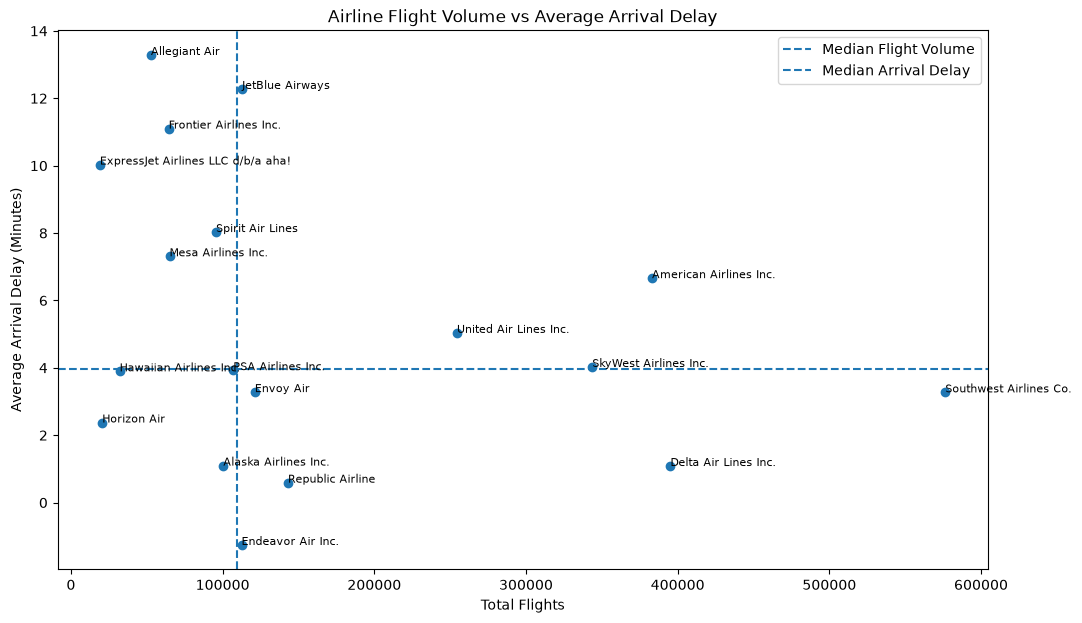

In [220]:
plt.figure(figsize=(12, 7))

plt.scatter(
    airline_kpi["TOTAL_FLIGHTS"],
    airline_kpi["AVG_ARR_DELAY"]
)

for _, row in airline_kpi.iterrows():
    plt.annotate(
        row["AIRLINE"],
        (
            row["TOTAL_FLIGHTS"],
            row["AVG_ARR_DELAY"]
        ),
        fontsize=8
    )

plt.axvline(
    airline_volume_threshold,
    linestyle="--",
    label="Median Flight Volume"
)

plt.axhline(
    airline_delay_threshold,
    linestyle="--",
    label="Median Arrival Delay"
)

plt.title("Airline Flight Volume vs Average Arrival Delay")
plt.xlabel("Total Flights")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.legend()

plt.show()

In [221]:
airport_kpi[
    [
        "ORIGIN",
        "TOTAL_FLIGHTS",
        "AVG_ARR_DELAY",
        "CANCELLATION_RATE",
        "DIVERSION_RATE"
    ]
]

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,CANCELLATION_RATE,DIVERSION_RATE
0,ABE,2023,1.535333,2.521008,0.247158
1,ABI,901,6.550343,2.996670,0.000000
2,ABQ,9284,3.598339,2.520465,0.215424
3,ABR,332,7.625000,1.204819,0.000000
4,ABY,436,-2.437209,1.146789,0.229358
...,...,...,...,...,...
375,XNA,4980,7.111180,2.469880,0.361446
376,XWA,433,15.063107,4.387991,0.461894
377,YAK,323,0.520767,2.167183,0.928793
378,YKM,152,1.979730,2.631579,0.000000


In [222]:
airport_kpi = airport_kpi.merge(
    airport_severe_rate,
    on="ORIGIN",
    how="left"
)

airport_kpi

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,TOTAL_ARR_DELAY_MINUTES,CANCELLATION_RATE,DIVERSION_RATE,DELAYED_FLIGHT_RATE,SEVERE_DELAY_RATE_x,DISRUPTION_RATE,SEVERE_DELAY_RATE_y
0,ABE,2023,1.535333,3020.0,2.521008,0.247158,27.978250,5.832921,2.768166,0.058329
1,ABI,901,6.550343,5725.0,2.996670,0.000000,35.738069,6.548280,2.996670,0.065483
2,ABQ,9284,3.598339,32493.0,2.520465,0.215424,30.859543,4.814735,2.735890,0.048147
3,ABR,332,7.625000,2501.0,1.204819,0.000000,21.987952,6.024096,1.204819,0.060241
4,ABY,436,-2.437209,-1048.0,1.146789,0.229358,19.724771,3.440367,1.376147,0.034404
...,...,...,...,...,...,...,...,...,...,...
375,XNA,4980,7.111180,34411.0,2.469880,0.361446,33.212851,6.767068,2.831325,0.067671
376,XWA,433,15.063107,6206.0,4.387991,0.461894,31.870670,8.314088,4.849885,0.083141
377,YAK,323,0.520767,163.0,2.167183,0.928793,31.269350,3.715170,3.095975,0.037152
378,YKM,152,1.979730,293.0,2.631579,0.000000,31.578947,1.973684,2.631579,0.019737


In [223]:
airport_volume_threshold = airport_kpi["TOTAL_FLIGHTS"].median()

airport_volume_threshold

np.float64(1130.0)

In [224]:
airport_kpi["VOLUME_SEGMENT"] = np.where(
    airport_kpi["TOTAL_FLIGHTS"] >= airport_volume_threshold,
    "High Volume",
    "Lower Volume"
)

In [225]:
airport_kpi = airport_kpi.merge(
    airport_severe_rate,
    on="ORIGIN",
    how="left"
)

airport_kpi.columns

Index(['ORIGIN', 'TOTAL_FLIGHTS', 'AVG_ARR_DELAY', 'TOTAL_ARR_DELAY_MINUTES',
       'CANCELLATION_RATE', 'DIVERSION_RATE', 'DELAYED_FLIGHT_RATE',
       'SEVERE_DELAY_RATE_x', 'DISRUPTION_RATE', 'SEVERE_DELAY_RATE_y',
       'VOLUME_SEGMENT', 'SEVERE_DELAY_RATE'],
      dtype='str')

In [226]:
airport_kpi[
    [
        "ORIGIN",
        "TOTAL_FLIGHTS",
        "AVG_ARR_DELAY",
        "SEVERE_DELAY_RATE",
        "CANCELLATION_RATE",
        "DIVERSION_RATE"
    ]
]

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,SEVERE_DELAY_RATE,CANCELLATION_RATE,DIVERSION_RATE
0,ABE,2023,1.535333,0.058329,2.521008,0.247158
1,ABI,901,6.550343,0.065483,2.996670,0.000000
2,ABQ,9284,3.598339,0.048147,2.520465,0.215424
3,ABR,332,7.625000,0.060241,1.204819,0.000000
4,ABY,436,-2.437209,0.034404,1.146789,0.229358
...,...,...,...,...,...,...
375,XNA,4980,7.111180,0.067671,2.469880,0.361446
376,XWA,433,15.063107,0.083141,4.387991,0.461894
377,YAK,323,0.520767,0.037152,2.167183,0.928793
378,YKM,152,1.979730,0.019737,2.631579,0.000000


In [227]:
airport_volume_threshold = airport_kpi["TOTAL_FLIGHTS"].median()

airport_volume_threshold

np.float64(1130.0)

In [228]:
airport_delay_threshold = airport_kpi["AVG_ARR_DELAY"].median()

airport_severe_threshold = airport_kpi["SEVERE_DELAY_RATE"].median()

airport_cancel_threshold = airport_kpi["CANCELLATION_RATE"].median()

airport_diversion_threshold = airport_kpi["DIVERSION_RATE"].median()

(
    airport_delay_threshold,
    airport_severe_threshold,
    airport_cancel_threshold,
    airport_diversion_threshold
)

(np.float64(3.7082145945273046),
 np.float64(0.05852361018615419),
 np.float64(2.785645371139167),
 np.float64(0.21608810260377675))

In [229]:
airport_kpi["HIGH_DELAY"] = (
    airport_kpi["AVG_ARR_DELAY"] > airport_delay_threshold
)

airport_kpi["HIGH_SEVERE_DELAY"] = (
    airport_kpi["SEVERE_DELAY_RATE"] > airport_severe_threshold
)

airport_kpi["HIGH_CANCELLATION"] = (
    airport_kpi["CANCELLATION_RATE"] > airport_cancel_threshold
)

airport_kpi["HIGH_DIVERSION"] = (
    airport_kpi["DIVERSION_RATE"] > airport_diversion_threshold
)

In [230]:
airport_kpi["POOR_RELIABILITY_INDICATORS"] = (
    airport_kpi[
        [
            "HIGH_DELAY",
            "HIGH_SEVERE_DELAY",
            "HIGH_CANCELLATION",
            "HIGH_DIVERSION"
        ]
    ]
    .sum(axis=1)
)

airport_kpi[
    [
        "ORIGIN",
        "TOTAL_FLIGHTS",
        "AVG_ARR_DELAY",
        "SEVERE_DELAY_RATE",
        "CANCELLATION_RATE",
        "DIVERSION_RATE",
        "POOR_RELIABILITY_INDICATORS"
    ]
]

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,SEVERE_DELAY_RATE,CANCELLATION_RATE,DIVERSION_RATE,POOR_RELIABILITY_INDICATORS
0,ABE,2023,1.535333,0.058329,2.521008,0.247158,1
1,ABI,901,6.550343,0.065483,2.996670,0.000000,3
2,ABQ,9284,3.598339,0.048147,2.520465,0.215424,0
3,ABR,332,7.625000,0.060241,1.204819,0.000000,2
4,ABY,436,-2.437209,0.034404,1.146789,0.229358,1
...,...,...,...,...,...,...,...
375,XNA,4980,7.111180,0.067671,2.469880,0.361446,3
376,XWA,433,15.063107,0.083141,4.387991,0.461894,4
377,YAK,323,0.520767,0.037152,2.167183,0.928793,1
378,YKM,152,1.979730,0.019737,2.631579,0.000000,0


In [231]:
high_volume_poor_airports = airport_kpi[
    (airport_kpi["VOLUME_SEGMENT"] == "High Volume")
    & (airport_kpi["POOR_RELIABILITY_INDICATORS"] >= 2)
].sort_values(
    [
        "POOR_RELIABILITY_INDICATORS",
        "TOTAL_FLIGHTS"
    ],
    ascending=[False, False]
)

high_volume_poor_airports[
    [
        "ORIGIN",
        "TOTAL_FLIGHTS",
        "AVG_ARR_DELAY",
        "SEVERE_DELAY_RATE",
        "CANCELLATION_RATE",
        "DIVERSION_RATE",
        "POOR_RELIABILITY_INDICATORS"
    ]
]

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,SEVERE_DELAY_RATE,CANCELLATION_RATE,DIVERSION_RATE,POOR_RELIABILITY_INDICATORS
100,DFW,130334,8.376381,0.072276,3.220188,0.278515,4
261,ORD,122296,6.062906,0.070280,3.096585,0.246124,4
96,DCA,53283,3.965573,0.066588,3.323762,0.240227,4
123,EWR,52989,8.666155,0.091302,3.872502,0.243447,4
357,TPA,32652,5.030588,0.060915,2.860468,0.220507,4
...,...,...,...,...,...,...,...
238,MLI,1856,-0.017897,0.063039,3.502155,0.161638,2
105,DRO,1585,8.380117,0.076972,2.776025,0.126183,2
231,MGM,1345,4.674489,0.071375,1.710037,0.074349,2
34,BFL,1191,7.695164,0.069689,2.602855,0.167926,2


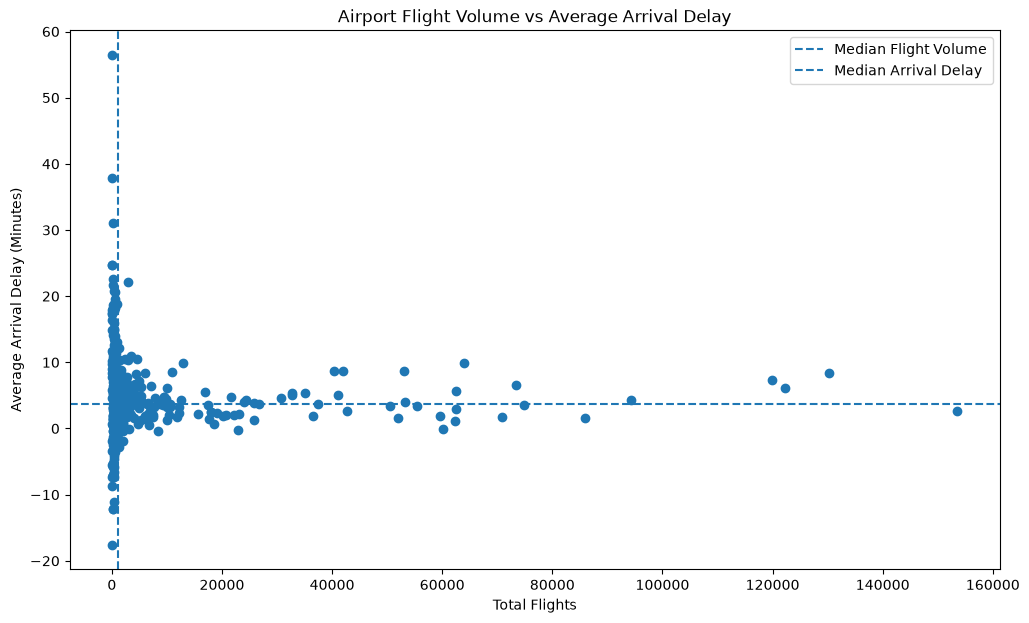

In [232]:
plt.figure(figsize=(12, 7))

plt.scatter(
    airport_kpi["TOTAL_FLIGHTS"],
    airport_kpi["AVG_ARR_DELAY"]
)

plt.axvline(
    airport_volume_threshold,
    linestyle="--",
    label="Median Flight Volume"
)

plt.axhline(
    airport_delay_threshold,
    linestyle="--",
    label="Median Arrival Delay"
)

plt.title("Airport Flight Volume vs Average Arrival Delay")
plt.xlabel("Total Flights")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.legend()

plt.show()

In [233]:
high_volume_poor_airports[
    [
        "ORIGIN",
        "TOTAL_FLIGHTS",
        "AVG_ARR_DELAY",
        "SEVERE_DELAY_RATE",
        "CANCELLATION_RATE",
        "DIVERSION_RATE"
    ]
].head(15)

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,SEVERE_DELAY_RATE,CANCELLATION_RATE,DIVERSION_RATE
100,DFW,130334,8.376381,0.072276,3.220188,0.278515
261,ORD,122296,6.062906,0.070280,3.096585,0.246124
96,DCA,53283,3.965573,0.066588,3.323762,0.240227
123,EWR,52989,8.666155,0.091302,3.872502,0.243447
357,TPA,32652,5.030588,0.060915,2.860468,0.220507
311,RSW,16891,5.487956,0.064709,3.155527,0.254573
270,PBI,10987,8.552108,0.078820,3.194685,0.300355
228,MEM,9944,6.101818,0.061545,2.966613,0.241352
38,BHM,7061,6.434401,0.064014,2.903271,0.269084
294,PVD,6517,3.921195,0.063373,3.191653,0.230167


In [234]:
airline_volume_threshold

np.float64(109756.5)

In [235]:
airline_delay_threshold, airline_severe_threshold, airline_cancel_threshold, airline_diversion_threshold

(np.float64(3.9759831850628045),
 np.float64(5.907443527834178),
 np.float64(2.638703222050834),
 np.float64(0.24318553792369735))

In [236]:
high_volume_poor_airlines

,AIRLINE,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,CANCELLATION_RATE,DIVERSION_RATE,SEVERE_DELAY_RATE,VOLUME_SEGMENT,HIGH_DELAY,HIGH_SEVERE_DELAY,HIGH_CANCELLATION,HIGH_DIVERSION,POOR_RELIABILITY_INDICATORS
2,American Airlines Inc.,383106,12.609895,6.661229,2.846993,0.256065,6.714852,High Volume,True,True,True,True,4
10,JetBlue Airways,112844,18.322555,12.276125,2.693098,0.317252,10.816703,High Volume,True,True,True,True,4
17,United Air Lines Inc.,254504,11.217032,5.035985,2.175211,0.274259,6.654119,High Volume,True,True,False,True,3
14,SkyWest Airlines Inc.,343737,9.458294,4.023311,2.253176,0.292666,5.872804,High Volume,True,False,False,True,2
5,Envoy Air,121256,6.728256,3.278914,2.996140,0.256482,5.178300,High Volume,False,False,True,True,2


In [237]:
airport_volume_threshold

np.float64(1130.0)

In [238]:
high_volume_poor_airports

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,TOTAL_ARR_DELAY_MINUTES,CANCELLATION_RATE,DIVERSION_RATE,DELAYED_FLIGHT_RATE,SEVERE_DELAY_RATE_x,DISRUPTION_RATE,SEVERE_DELAY_RATE_y,VOLUME_SEGMENT,SEVERE_DELAY_RATE,HIGH_DELAY,HIGH_SEVERE_DELAY,HIGH_CANCELLATION,HIGH_DIVERSION,POOR_RELIABILITY_INDICATORS
100,DFW,130334,8.376381,1053531.0,3.220188,0.278515,36.975770,7.227585,3.498703,0.072276,High Volume,0.072276,True,True,True,True,4
261,ORD,122296,6.062906,716684.0,3.096585,0.246124,34.404232,7.028030,3.342709,0.070280,High Volume,0.070280,True,True,True,True,4
96,DCA,53283,3.965573,203767.0,3.323762,0.240227,31.460316,6.658784,3.563989,0.066588,High Volume,0.066588,True,True,True,True,4
123,EWR,52989,8.666155,440310.0,3.872502,0.243447,36.603823,9.130197,4.115949,0.091302,High Volume,0.091302,True,True,True,True,4
357,TPA,32652,5.030588,159198.0,2.860468,0.220507,31.976602,6.091510,3.080975,0.060915,High Volume,0.060915,True,True,True,True,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
238,MLI,1856,-0.017897,-32.0,3.502155,0.161638,24.245690,6.303879,3.663793,0.063039,High Volume,0.063039,False,True,True,False,2
105,DRO,1585,8.380117,12897.0,2.776025,0.126183,35.331230,7.697161,2.902208,0.076972,High Volume,0.076972,True,True,False,False,2
231,MGM,1345,4.674489,6175.0,1.710037,0.074349,29.962825,7.137546,1.784387,0.071375,High Volume,0.071375,True,True,False,False,2
34,BFL,1191,7.695164,8911.0,2.602855,0.167926,26.112510,6.968934,2.770781,0.069689,High Volume,0.069689,True,True,False,False,2


In [239]:
airport_kpi_clean = airport_kpi.loc[
    :,
    [
        "ORIGIN",
        "TOTAL_FLIGHTS",
        "AVG_ARR_DELAY",
        "CANCELLATION_RATE",
        "DIVERSION_RATE",
        "SEVERE_DELAY_RATE",
        "POOR_RELIABILITY_INDICATORS"
    ]
].copy()

airport_kpi_clean.sort_values(
    ["POOR_RELIABILITY_INDICATORS", "TOTAL_FLIGHTS"],
    ascending=[False, False]
).head(20)

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,CANCELLATION_RATE,DIVERSION_RATE,SEVERE_DELAY_RATE,POOR_RELIABILITY_INDICATORS
100,DFW,130334,8.376381,3.220188,0.278515,0.072276,4
261,ORD,122296,6.062906,3.096585,0.246124,0.070280,4
96,DCA,53283,3.965573,3.323762,0.240227,0.066588,4
123,EWR,52989,8.666155,3.872502,0.243447,0.091302,4
357,TPA,32652,5.030588,2.860468,0.220507,0.060915,4
311,RSW,16891,5.487956,3.155527,0.254573,0.064709,4
270,PBI,10987,8.552108,3.194685,0.300355,0.078820,4
228,MEM,9944,6.101818,2.966613,0.241352,0.061545,4
38,BHM,7061,6.434401,2.903271,0.269084,0.064014,4
294,PVD,6517,3.921195,3.191653,0.230167,0.063373,4


In [240]:
airport_kpi.columns.tolist()

['ORIGIN',
 'TOTAL_FLIGHTS',
 'AVG_ARR_DELAY',
 'TOTAL_ARR_DELAY_MINUTES',
 'CANCELLATION_RATE',
 'DIVERSION_RATE',
 'DELAYED_FLIGHT_RATE',
 'SEVERE_DELAY_RATE_x',
 'DISRUPTION_RATE',
 'SEVERE_DELAY_RATE_y',
 'VOLUME_SEGMENT',
 'SEVERE_DELAY_RATE',
 'HIGH_DELAY',
 'HIGH_SEVERE_DELAY',
 'HIGH_CANCELLATION',
 'HIGH_DIVERSION',
 'POOR_RELIABILITY_INDICATORS']

In [241]:
airport_bq6 = airport_kpi[
    [
        "ORIGIN",
        "TOTAL_FLIGHTS",
        "AVG_ARR_DELAY",
        "CANCELLATION_RATE",
        "DIVERSION_RATE",
        "SEVERE_DELAY_RATE",
        "POOR_RELIABILITY_INDICATORS"
    ]
].copy()

airport_bq6 = airport_bq6.sort_values(
    ["POOR_RELIABILITY_INDICATORS", "TOTAL_FLIGHTS"],
    ascending=[False, False]
)

airport_bq6.head(20)

,ORIGIN,TOTAL_FLIGHTS,AVG_ARR_DELAY,CANCELLATION_RATE,DIVERSION_RATE,SEVERE_DELAY_RATE,POOR_RELIABILITY_INDICATORS
100,DFW,130334,8.376381,3.220188,0.278515,0.072276,4
261,ORD,122296,6.062906,3.096585,0.246124,0.070280,4
96,DCA,53283,3.965573,3.323762,0.240227,0.066588,4
123,EWR,52989,8.666155,3.872502,0.243447,0.091302,4
357,TPA,32652,5.030588,2.860468,0.220507,0.060915,4
311,RSW,16891,5.487956,3.155527,0.254573,0.064709,4
270,PBI,10987,8.552108,3.194685,0.300355,0.078820,4
228,MEM,9944,6.101818,2.966613,0.241352,0.061545,4
38,BHM,7061,6.434401,2.903271,0.269084,0.064014,4
294,PVD,6517,3.921195,3.191653,0.230167,0.063373,4


### Segmentation Method

High-volume segments were defined using the median total flight volume within
the dataset. Poor reliability was identified by comparing average arrival delay,
severe-delay rate, cancellation rate, and diversion rate against their respective
dataset medians.

A segment was classified as high-volume and poor-reliability when it was above
the median volume threshold and had at least two reliability indicators above
their corresponding median benchmarks.

These thresholds are analytical segmentation rules created for this project.
They are not universal airline or airport industry standards.

## Final Business Answer

### Which airline or airport segments combine high volume with poor reliability?

The analysis identifies several airline and airport segments that combine
relatively high operational volume with multiple indicators of poor
reliability.

At the airline level, **American Airlines Inc., JetBlue Airways, United Air
Lines Inc., SkyWest Airlines Inc., and Envoy Air** were classified as
high-volume airlines with at least two reliability indicators above their
respective dataset median benchmarks.

American Airlines had the largest volume among these flagged airlines, with
**383,106 flights**, while JetBlue recorded the highest average arrival delay
(**12.28 minutes**) and severe-delay rate (**10.82%**) within this group.

At the airport level, **DFW, ORD, DCA, EWR, TPA, RSW, PBI, and other airports**
were identified as high-volume segments with multiple reliability indicators
above the dataset benchmarks. DFW handled **130,334 flights** and recorded an
average arrival delay of **8.38 minutes**, while EWR recorded a higher average
arrival delay of **8.67 minutes** and a severe-delay rate of **9.13%**.

The analysis also shows that some lower-volume airports can have substantially
higher reliability problems. For example, ASE recorded an average arrival
delay of **22.21 minutes** and a severe-delay rate of **9.48%**, despite having
only **2,859 flights**. Therefore, operational attention should distinguish
between high-volume segments with broad operational exposure and lower-volume
segments with concentrated reliability problems.

Overall, the results indicate that high-volume segments with multiple poor
reliability indicators represent important areas for operational monitoring,
while smaller airports with extreme delay or disruption indicators may require
more targeted intervention.

The segmentation uses dataset-specific median thresholds and is intended as
an analytical framework for this project rather than a universal industry
standard.

# Business Question 7

## What practical actions should management prioritize?

### Objective

Translate the findings from airline, airport, route, delay-cause, seasonal,
and reliability analyses into practical management actions.

The recommendations are based on observed operational patterns in the dataset
and are intended to support operational monitoring, resource planning, delay
reduction, and targeted intervention.

The recommendations are descriptive and diagnostic. They do not establish
causal relationships or guarantee that a specific intervention will reduce
delays.

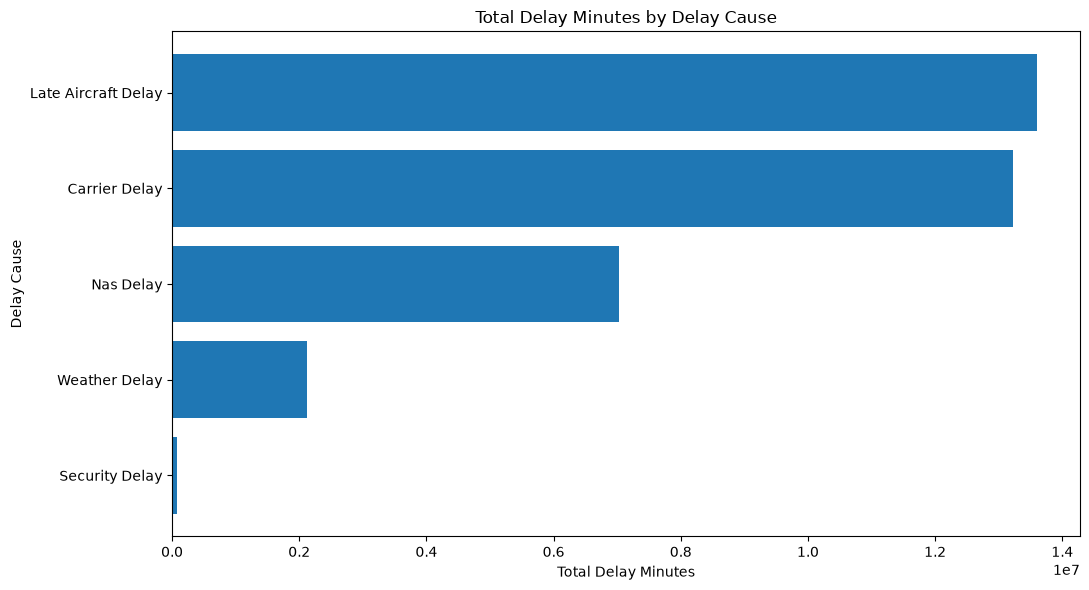

In [242]:
delay_cause_chart = delay_cause_totals.copy()

delay_cause_chart["DELAY_CAUSE"] = (
    delay_cause_chart["DELAY_CAUSE"]
    .str.replace("DELAY_DUE_", "", regex=False)
    .str.replace("_", " ")
    .str.title()
)

delay_cause_chart = delay_cause_chart.sort_values(
    "TOTAL_DELAY_MINUTES",
    ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    delay_cause_chart["DELAY_CAUSE"],
    delay_cause_chart["TOTAL_DELAY_MINUTES"]
)

plt.title("Total Delay Minutes by Delay Cause")
plt.xlabel("Total Delay Minutes")
plt.ylabel("Delay Cause")

plt.tight_layout()
plt.show()

### Interpretation

Late-aircraft and carrier-related delays represent the largest sources of
cause-attributed delay minutes in the dataset.

Together, these two causes account for approximately 74.39% of
cause-attributed delay minutes.

This indicates that management attention should first examine aircraft
turnaround/rotation processes and carrier-controlled operational processes,
while NAS, weather, and security remain additional sources of disruption.

In [246]:
month_kpi = (
    cleaned_df.groupby("MONTH")
    .agg(
        TOTAL_FLIGHTS=("FL_DATE", "count"),
        AVG_DEP_DELAY=("DEP_DELAY", "mean"),
        AVG_ARR_DELAY=("ARR_DELAY", "mean"),
        DELAYED_FLIGHT_RATE=("ARR_DELAY", lambda x: (x > 0).mean()),
        CANCELLATION_RATE=("CANCELLED", "mean"),
        DIVERSION_RATE=("DIVERTED", "mean")
    )
    .reset_index()
)

month_kpi

,MONTH,TOTAL_FLIGHTS,AVG_DEP_DELAY,AVG_ARR_DELAY,DELAYED_FLIGHT_RATE,CANCELLATION_RATE,DIVERSION_RATE
0,1,268702,8.718996,2.190728,0.305681,0.027343,0.002121
1,2,248497,9.823191,3.712646,0.323988,0.028926,0.002145
2,3,293099,8.320393,2.255956,0.304314,0.050290,0.001822
3,4,253917,9.597162,3.539976,0.304548,0.068511,0.002091
4,5,252530,9.425539,3.359411,0.319162,0.017190,0.002606
5,6,261136,15.047865,10.061753,0.387668,0.020127,0.003378
6,7,284968,14.666483,9.491415,0.370821,0.017886,0.003369
7,8,287104,11.846190,6.453106,0.342413,0.019860,0.002783
8,9,206928,5.776012,-0.512181,0.267480,0.012831,0.001894
9,10,216790,7.330811,1.424036,0.305346,0.010849,0.001767


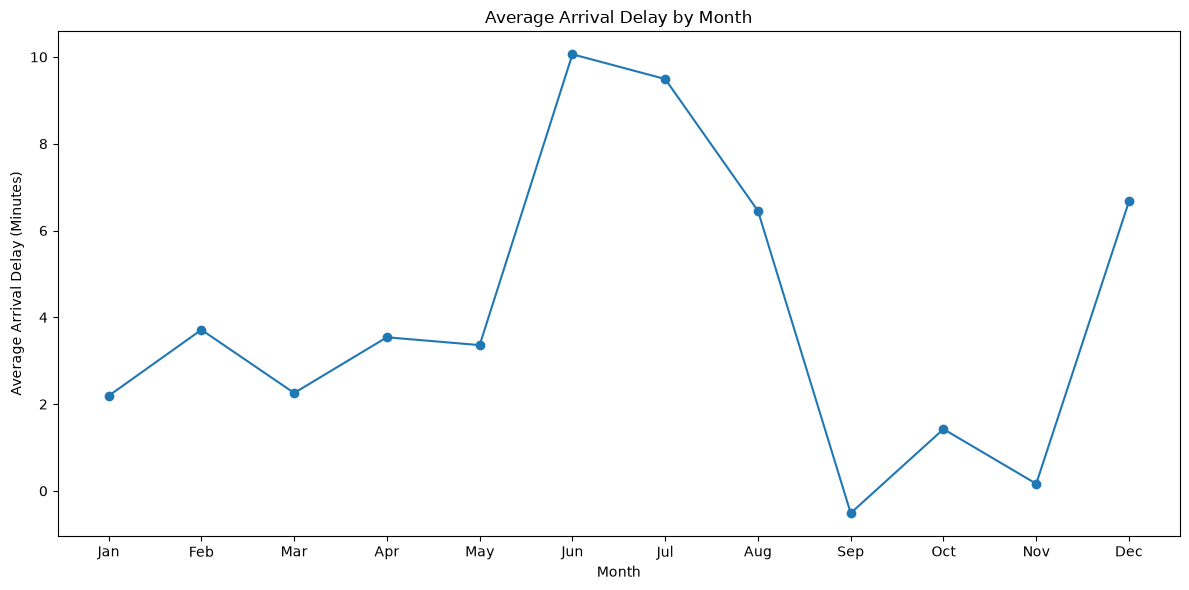

In [247]:
monthly_plot = month_kpi.sort_values("MONTH")

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_plot["MONTH"],
    monthly_plot["AVG_ARR_DELAY"],
    marker="o"
)

plt.title("Average Arrival Delay by Month")
plt.xlabel("Month")
plt.ylabel("Average Arrival Delay (Minutes)")

plt.xticks(
    monthly_plot["MONTH"],
    [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.tight_layout()
plt.show()

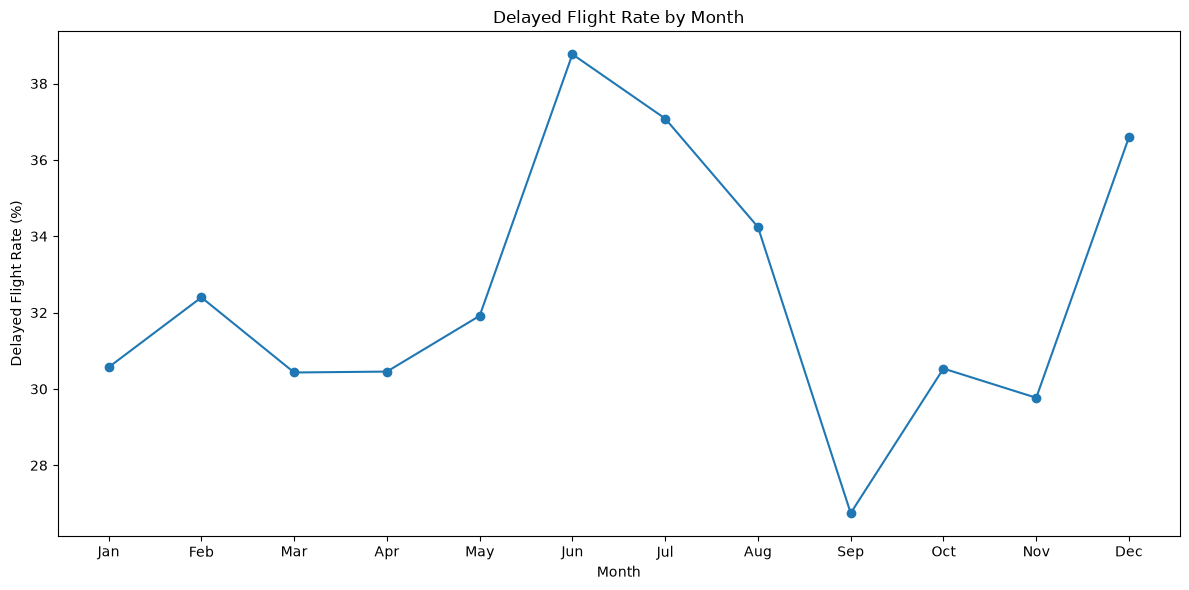

In [248]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_plot["MONTH"],
    monthly_plot["DELAYED_FLIGHT_RATE"] * 100,
    marker="o"
)

plt.title("Delayed Flight Rate by Month")
plt.xlabel("Month")
plt.ylabel("Delayed Flight Rate (%)")

plt.xticks(
    range(1, 13),
    [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.tight_layout()
plt.show()

### Interpretation

The monthly trend shows elevated delay exposure during the summer period.

June recorded the highest average arrival delay at approximately 10.06 minutes
and the highest delayed-flight rate at approximately 38.77%.

July also showed elevated delay exposure, with an average arrival delay of
approximately 9.49 minutes and a delayed-flight rate of approximately 37.08%.

This supports using June and July as periods for enhanced operational
monitoring and resource planning.

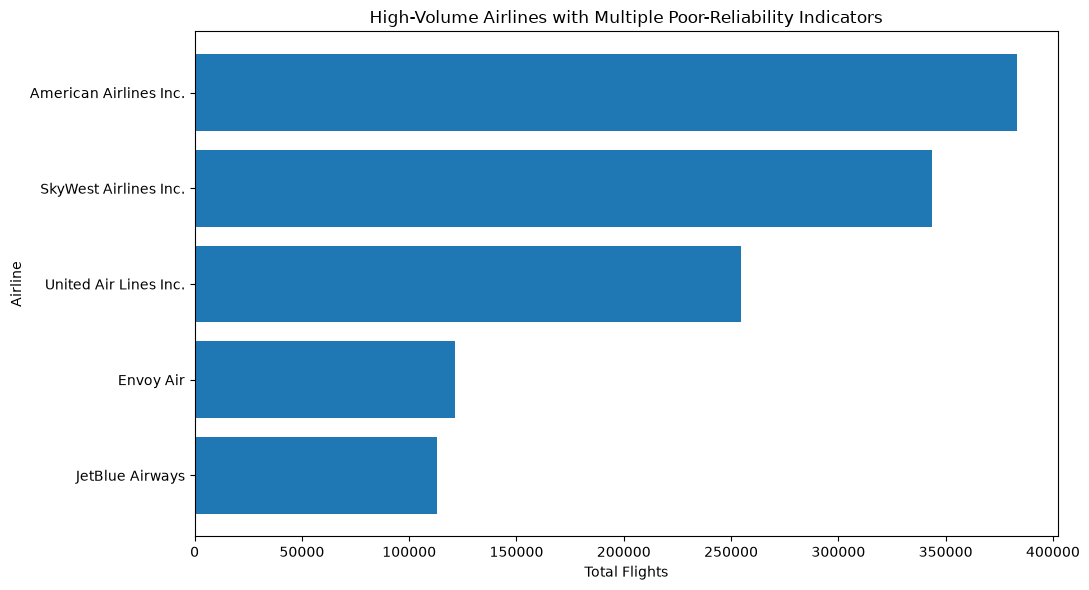

In [250]:
airline_action_plot = high_volume_poor_airlines.sort_values(
    "TOTAL_FLIGHTS",
    ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    airline_action_plot["AIRLINE"],
    airline_action_plot["TOTAL_FLIGHTS"]
)

plt.title("High-Volume Airlines with Multiple Poor-Reliability Indicators")
plt.xlabel("Total Flights")
plt.ylabel("Airline")

plt.tight_layout()
plt.show()

### Interpretation

The high-volume airline analysis identifies segments where reliability issues
occur alongside substantial operational activity.

American Airlines has the largest flight volume among the flagged airlines,
while JetBlue has the highest average arrival delay and severe-delay rate
within this group.

These segments can therefore be considered candidates for deeper operational
review, with attention to the specific reliability indicators contributing to
their classification.

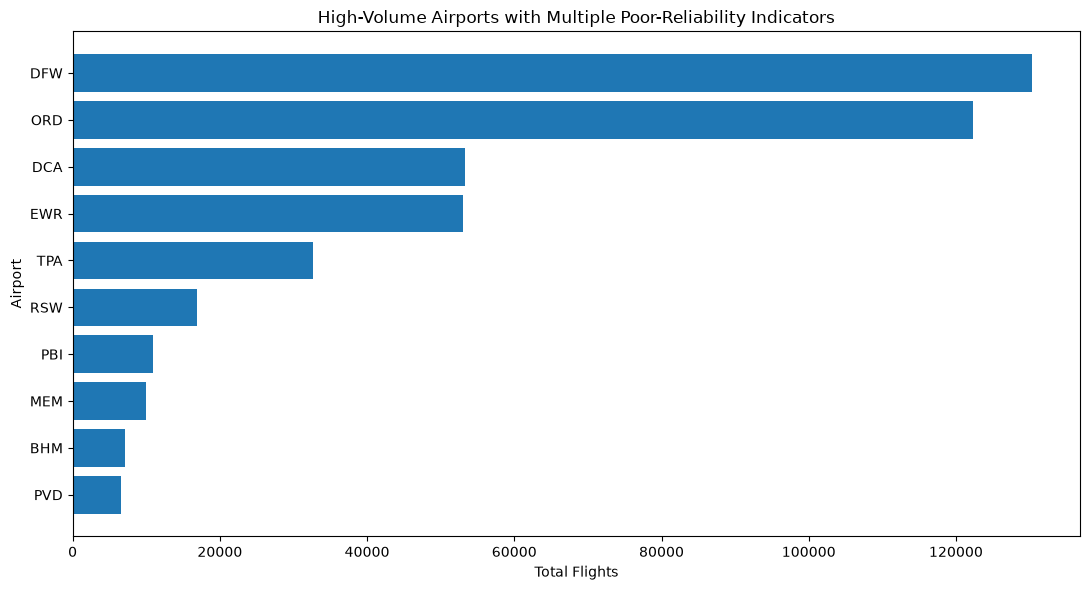

In [252]:
airport_action_plot = airport_bq6.head(10).sort_values(
    "TOTAL_FLIGHTS",
    ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    airport_action_plot["ORIGIN"],
    airport_action_plot["TOTAL_FLIGHTS"]
)

plt.title(
    "High-Volume Airports with Multiple Poor-Reliability Indicators"
)
plt.xlabel("Total Flights")
plt.ylabel("Airport")

plt.tight_layout()
plt.show()

### Interpretation

High-volume airports with multiple poor-reliability indicators represent
important areas for operational monitoring because reliability issues at
high-activity airports can affect a large number of flight operations.

DFW and ORD stand out because of their large flight volumes, while EWR also
shows relatively high average arrival delay and severe-delay exposure.

Smaller airports such as ASE may show more extreme reliability problems, but
their lower flight volume means that their operational response may be more
targeted rather than network-wide.

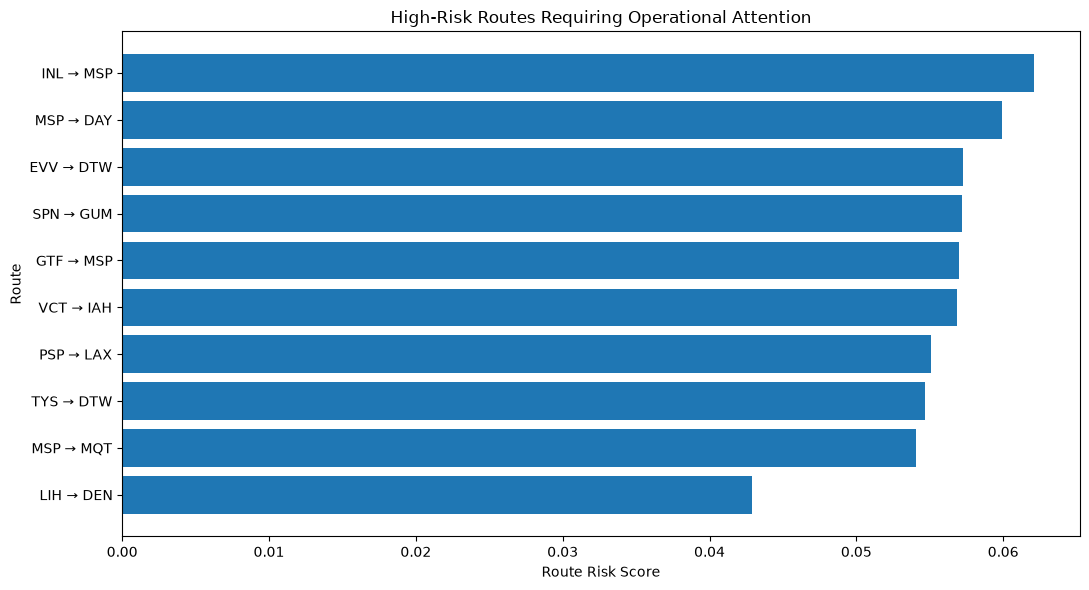

In [254]:
route_action_plot = high_risk_routes.sort_values(
    "ROUTE_RISK_SCORE",
    ascending=True
).head(10)

plt.figure(figsize=(11, 6))

plt.barh(
    route_action_plot["ROUTE"],
    route_action_plot["ROUTE_RISK_SCORE"]
)

plt.title("High-Risk Routes Requiring Operational Attention")
plt.xlabel("Route Risk Score")
plt.ylabel("Route")

plt.tight_layout()
plt.show()

In [255]:
[x for x in globals() if "route" in x.lower()]

['route_kpi',
 'route_delay_rate',
 'route_severe_rate',
 'top_delayed_routes',
 'route_score',
 'route_ranking',
 'high_risk_routes',
 'route_action_plot']

### Interpretation

The route analysis identifies specific origin-destination pairs with
relatively high delay frequency, delay severity, and disruption exposure.

These routes should be reviewed at the route level rather than treating all
flights within an airline or airport as equally exposed.

Operational review can focus on recurring delay patterns, aircraft rotation,
turnaround performance, and route-specific disruption exposure.

## Management Action Matrix

| Evidence | Observed Finding | Practical Management Action |
|---|---|---|
| Delay causes | Late-aircraft and carrier delays account for approximately 74.39% of cause-attributed delay minutes | Review aircraft rotation, turnaround, scheduling, crew/operational processes, and carrier-controlled delay drivers |
| Seasonal pattern | Summer has the highest average arrival delay, delayed-flight rate, and diversion rate | Increase operational monitoring, staffing, and contingency planning during summer |
| Monthly pattern | June and July show elevated delay exposure | Conduct pre-season capacity and resource planning before June-July |
| High-volume airlines | American, JetBlue, United, SkyWest, and Envoy combine high volume with multiple poor-reliability indicators | Conduct airline-specific operational reviews using delay, severe-delay, cancellation, and diversion KPIs |
| High-volume airports | DFW, ORD, DCA, EWR, and TPA show high volume with multiple poor-reliability indicators | Prioritize airport-level operational monitoring and bottleneck analysis |
| High-risk routes | Selected routes show elevated delay frequency/severity and disruption exposure | Perform route-specific operational reviews and monitor recurring problem routes |
| Weekday pattern | Friday has the highest average arrival delay and delayed-flight rate | Increase monitoring and operational readiness on high-risk weekdays |

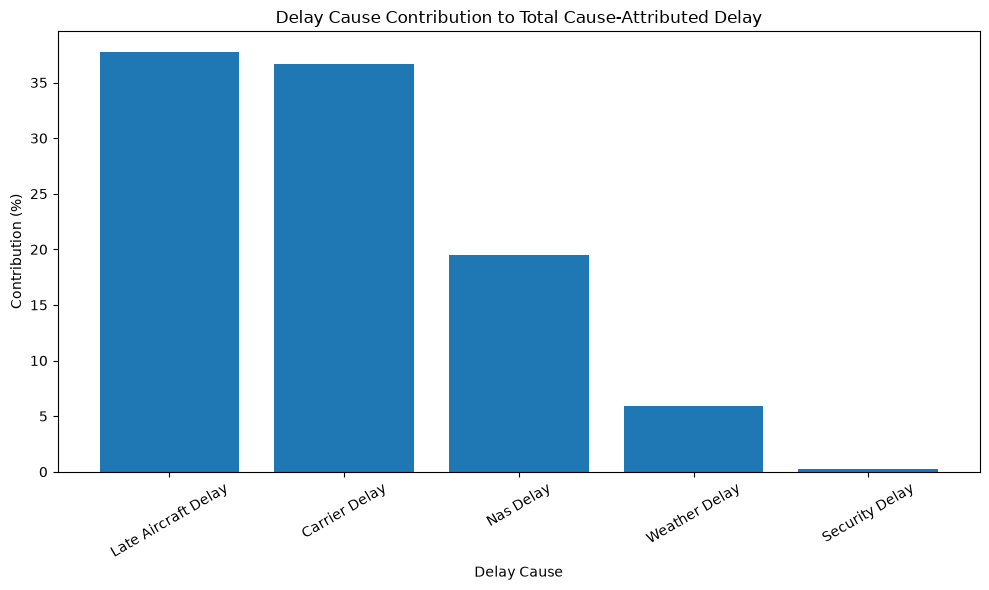

In [257]:
cause_summary = delay_cause_totals.copy()

cause_summary["DELAY_CAUSE"] = (
    cause_summary["DELAY_CAUSE"]
    .str.replace("DELAY_DUE_", "", regex=False)
    .str.replace("_", " ")
    .str.title()
)

cause_summary = cause_summary.sort_values(
    "CONTRIBUTION_PERCENT",
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.bar(
    cause_summary["DELAY_CAUSE"],
    cause_summary["CONTRIBUTION_PERCENT"]
)

plt.title("Delay Cause Contribution to Total Cause-Attributed Delay")
plt.xlabel("Delay Cause")
plt.ylabel("Contribution (%)")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## Final Business Answer

### What practical actions should management prioritize?

The findings across the analysis indicate several practical areas for
management attention.

### 1. Focus on late-aircraft and carrier-related delays

Late-aircraft delay contributed approximately **37.72%** of
cause-attributed delay minutes, while carrier delay contributed approximately
**36.67%**. Together, these two causes represented approximately **74.39%**
of cause-attributed delay minutes.

Management should therefore review aircraft rotation and turnaround processes,
schedule adherence, and carrier-controlled operational processes as important
areas for delay reduction.

### 2. Strengthen summer operational planning

Summer recorded the highest average arrival delay (**8.62 minutes**), delayed
flight rate (**36.63%**), and diversion rate (**0.32%**).

June was particularly important, recording an average arrival delay of
approximately **10.06 minutes**, a delayed-flight rate of **38.77%**, and an
average departure delay of **15.05 minutes**.

Management should therefore increase operational monitoring and contingency
planning before and during the June-July period.

### 3. Review high-volume airlines with multiple reliability issues

American Airlines, JetBlue Airways, United Air Lines, SkyWest Airlines, and
Envoy Air were identified as high-volume airlines with at least two
reliability indicators above the dataset median.

These airlines can be reviewed using airline-specific delay, severe-delay,
cancellation, and diversion KPIs rather than relying only on overall flight
volume.

### 4. Monitor high-volume airports

DFW, ORD, DCA, EWR, TPA and other high-volume airports showed multiple
reliability indicators above the dataset benchmarks.

Airport-level monitoring should focus on delay burden, severe delays,
cancellations, diversions, and recurring operational bottlenecks.

### 5. Conduct route-specific operational reviews

The route analysis identified specific origin-destination pairs with elevated
delay frequency, severity, and disruption exposure.

Management should monitor these routes separately because route-level
problems may not be visible when only airline-level or airport-level
aggregates are examined.

### 6. Prepare for high-risk weekdays

Friday recorded the highest average arrival delay (**5.95 minutes**) and
delayed-flight rate (**35.07%**) among weekdays.

Operational monitoring and resource planning can therefore be strengthened
during higher-risk weekday periods.

### Overall management direction

The analysis suggests that management attention should combine **cause-based,
seasonal, airline-level, airport-level, and route-level monitoring**.

The most important operational evidence comes from the concentration of
cause-attributed delay minutes in late-aircraft and carrier delays, elevated
summer delay exposure, and high-volume segments with multiple reliability
indicators.

These recommendations are based on descriptive and diagnostic patterns in
the dataset. They identify areas for operational review but do not establish
causality or guarantee that a specific intervention will reduce delays.